In [95]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from astropy.table import Table
from astropy.io import fits
from pygam import LinearGAM
from IPython.display import display, Markdown

from wavecal_stats import (
    SPEED_OF_LIGHT_KMS,
    barycentric_correction_kms,
    telluric_order_offsets,
    fit_star_velocities,
    velocity_corrected_residuals,
    clipped_order_stats,
)


<!-- # HOW TO USE

1. Set `INDIR` to the folder of spectra you wish to use, and `ARM` to `'VIS'` or `'NIR'`.
2. Set `STANDARD_STARS` to a dict mapping each library standard star to its own list of `[min, max]`
   stellar absorption-line windows (Å). Telluric lines are listed once in `TELLURIC_LINES_NAMED` and are
   measured in every exposure.
3. Run all cells. The per-order corrections (velocity-corrected) are written to
   `ORDER_CORRECTIONS_CSV_PATH`; every other output is written under `RESULTS_DIR`. -->

In [96]:
# FOLDER WHERE THE EXTRACTED MERGED SPECTRA LIVE
INDIR = './data/2026_june_july_standards_attached_arcs/'
# INDIR = './data/2026_june_july_standards_unattached_arcs/'
# INDIR = './data/2026_june_july_standards_unattached_arcs_w_skyline_fitting/'
ARM = 'VIS'  # 'VIS' or 'NIR'

TELLURIC_SPECTRUM = './reference/soxs_vis_r5000_telluric_spectrum.tsv'

# STANDARD STAR NAMES TO COMPARE AGAINST THEIR LIBRARY SPECTRA, MAPPED TO THE [MIN, MAX]
# WAVELENGTH WINDOWS (ANGSTROM) TO MEASURE/VISUALISE LINE MINIMA IN FOR THAT STAR.
# ONE COMPARISON PLOT IS GENERATED PER WINDOW WITH EVERY STAR TOGETHER (+ A PER-STAR METRICS PLOT WHEN PLOT_METRICS IS True).
# AVAILABLE STAR NAMES (FROM flux_standards.fits COLUMNS): GD71, LTT3218, GD153, EG274, LTT7987, Feige110, EG21
STANDARD_STAR_AKAS = {
    "LTT7987": "CD3017706",
    "EG274": "CD3810980",
    "LTT3218": "CD325613",
    "EG21": "CPD69177",
}

# STELLAR ABSORPTION-LINE WINDOWS [MIN, MAX] (ANGSTROM, AIR) PER STAR. EACH WINDOW IS COMPARED WITH THE SAME STAR'S
# REST-FRAME LIBRARY SPECTRUM. TELLURIC LINES ARE NOT LISTED HERE -- SEE TELLURIC_LINES_NAMED BELOW.
# TODO: GD71, LTT3218 AND GD153 HAVE NO WINDOWS DEFINED YET.
BALMER_WINDOWS = [[3965, 3975], [4098, 4108], [4335, 4345], [4856, 4866], [6558, 6568]]
STANDARD_STARS = {
    "GD71": BALMER_WINDOWS,
    "LTT3218": BALMER_WINDOWS,
    "GD153": BALMER_WINDOWS,
    "EG274": BALMER_WINDOWS,
    "LTT7987": BALMER_WINDOWS,
    "Feige110": [[3965, 3975], [4098, 4108], [4335, 4345], [4681, 4691], [4856, 4866], [5408, 5418], [5870, 5880], [7060, 7070]],
    "EG21": BALMER_WINDOWS,
}

TELLURIC_WINDOWS = [[5380,6750], [6710,8500],[6270, 6290], [6860, 6950], [7590, 7700]]
# TELLURIC_WINDOWS = [[3500, 3750], [3750, 4000], [4000, 4250], [4250, 4500], [4500, 4750], [4750, 5000], [5000, 5250], [5250, 5500], [5500, 5750], [5750, 6000], [6000, 6250], [6250, 6500], [6500, 6750], [6750, 7000], [7000, 7250], [7250, 7500], [7500, 7750], [7750, 8000], [8000, 8250], [8250, 8500]]


# TELLURIC ABSORPTION LINES (ANGSTROM, AIR). THESE FORM IN THE EARTH'S ATMOSPHERE, SO THEY DO NOT MOVE WITH THE
# STAR'S VELOCITY AND GIVE AN ABSOLUTE WAVELENGTH ANCHOR. THEY ARE MEASURED IN EVERY EXPOSURE AGAINST THE TELLURIC MODEL.
TELLURIC_LINES_NAMED = {
    "O2 gamma 6278": 6277.70,
    "O2 B 6868": 6868.47,
    "H2O 7253": 7252.95,
    "H2O 8228": 8228.27,
}
TELLURIC_LINES = list(TELLURIC_LINES_NAMED.values())
# HALF-WIDTH (ANGSTROM) OF THE WINDOW AROUND EACH TELLURIC LINE IN WHICH THE MINIMUM IS MEASURED.
TELLURIC_HALF_WINDOW_ANGSTROM = 7.0

# WHICH LINE TYPE ANCHORS EACH ORDER'S CORRECTION. R AND I HAVE TELLURIC LINES; U AND G ONLY HAVE STELLAR LINES,
# SO THEY USE THE VELOCITY-CORRECTED STELLAR LINES.
ORDER_ANCHORS = {'u': 'stellar', 'g': 'stellar', 'r': 'telluric', 'i': 'telluric'}

# STELLAR ABSORPTION LINES (ANGSTROM, AIR). USED ONLY TO NAME THE LINE IN THE COMPARISON PLOTS.
STELLAR_LINES_NAMED = {
    "Ca II K": 3933.66,
    "Ca II H": 3968.47,
    "H epsilon": 3970.07,
    "H delta": 4101.74,
    "H gamma": 4340.47,
    "He II 4686": 4685.71,
    "H beta": 4861.33,
    "Mg I b1": 5183.60,
    "He II 5411": 5411.52,
    "He I 5876": 5875.62,
    "Na D1": 5895.92,
    "H alpha": 6562.80,
    "He I 7065": 7065.19,
}

# EVERY NAMED LINE. plot_comparison LABELS THE MEASURED MINIMUM WITH THE NAMED LINE IN THE WINDOW THAT IS CLOSEST TO IT.
REFERENCE_LINES_NAMED = {**STELLAR_LINES_NAMED, **TELLURIC_LINES_NAMED}

# ROOT FOLDER FOR EVERY OUTPUT THIS NOTEBOOK PRODUCES.
RESULTS_DIR = "./results/"
PLOTS_DIR = RESULTS_DIR + "plots/"

# WHERE PER-SPECTRUM WAVELENGTH-SHIFT MEASUREMENTS ARE WRITTEN.
RESULTS_CSV_PATH = RESULTS_DIR + "std_check_wavelength_shifts.csv"

# WHERE SUMMARY TABLES ARE WRITTEN.
# ORDER_CORRECTIONS_CSV_PATH IS THE MAIN RESULT: VELOCITY-CORRECTED SHIFT AND SCATTER FOR EACH ORDER.
ORDER_CORRECTIONS_CSV_PATH = RESULTS_DIR + "std_check_order_corrections.csv"
ORDER_CORRECTIONS_RAW_CSV_PATH = RESULTS_DIR + "std_check_order_corrections_raw.csv"
STAR_VELOCITIES_CSV_PATH = RESULTS_DIR + "std_check_star_velocities.csv"
STAR_WINDOW_STATS_CSV_PATH = RESULTS_DIR + "std_check_stats_by_star_window.csv"

# SOXS SPECTRAL-FORMAT TABLE (PER-ORDER WAVELENGTH COVERAGE) FOR THE CURRENT ARM.
SPECTRAL_FORMAT_CSV_PATH = f"./reference/SOXS_SPECTRAL_FORMAT_TAB_{ARM}.csv"

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(PLOTS_DIR, exist_ok=True)

TELLURIC_COLOR = 'red'
MIN_LABEL_FONTSIZE = 13.5

ORDERS_TO_INSPECT = ['u', 'g', 'r', 'i']

# SLIT WIDTH (ARCSEC) USED FOR THE MAIN ANALYSIS (VELOCITY FIT, ORDER CORRECTIONS, TABLES AND COMPARISON PLOTS).
# SPECTRA FROM OTHER SLITS ARE LOADED TOO, BUT ONLY FEED THE TELLURIC SHIFT DIAGNOSTIC PLOT.
PRIMARY_SLIT = 1.0

# PLOT COLOUR FOR EACH QUASI-ORDER, AND PLOT MARKER FOR EACH SLIT WIDTH (OTHER SLITS USE '^')
ORDER_COLORS = {'u': 'tab:purple', 'g': 'tab:green', 'r': 'tab:red', 'i': 'tab:brown'}
SLIT_MARKERS = {1.0: 'o', 5.0: 's'}
# PLOT MARKER FOR EACH QUASI-ORDER IN THE STAR VELOCITY DIAGNOSTIC PLOT (OTHER ORDERS USE '^')
ORDER_MARKERS = {'u': 'v', 'g': 'D', 'r': 'o', 'i': 's'}
# COLOURS GIVEN TO THE LOADED STARS (IN STANDARD_STARS ORDER) IN THE MERGED COMPARISON AND TELLURIC SANITY-CHECK PLOTS. RED IS LEFT OUT: IT IS THE TELLURIC MODEL.
STAR_PALETTE = ['tab:blue', 'tab:orange', 'tab:green', 'tab:purple', 'tab:brown', 'tab:pink', 'tab:olive', 'tab:cyan']
# ORDERS_TO_INSPECT = ['g', 'u']

# SET TO True TO ALSO WRITE THE SHIFT-VS-HEADER-PROPERTY METRICS PLOTS (*_metrics.png) FOR EACH STAR/WINDOW.
PLOT_METRICS = False

HEADER = f"""
"
# SOXS {ARM} Wavelength Calibration Investigation - THREE

## Data Reduction Setup

SOXSPIPE v0.17.4

❌ Attached arcs  
✅ Skyline wavelength calibration  
❌ Improved Horne Extraction  

"""

In [97]:
display(Markdown(HEADER))


"
# SOXS VIS Wavelength Calibration Investigation - THREE

## Data Reduction Setup

SOXSPIPE v0.17.4

❌ Attached arcs  
✅ Skyline wavelength calibration  
❌ Improved Horne Extraction  



In [98]:
# LIBRARY FLUX STANDARD DATA FROM SOXSPIPE
data = Table.read('./reference/flux_standards.fits', hdu = 1)
# REFERENCE TELLURIC MODEL SPECTRUM (WAVELENGTH IN ANGSTROM, CONTINUUM-NORMALIZED FLUX)
telluricSpectrumDf = pd.read_csv(TELLURIC_SPECTRUM, sep='\t', comment='#', names=['WaveAngstrom', 'NormFlux'])
telluricSpectrumWaveAngstrom = telluricSpectrumDf['WaveAngstrom'].to_numpy()
telluricSpectrumFlux = telluricSpectrumDf['NormFlux'].to_numpy()


In [99]:
# LIST FITS FILES IN THE INDIVIDUAL SPECTRA FOLDER
fls = [f for f in os.listdir(INDIR) if f.endswith('.fits')]


In [100]:
# GRAB PROPERTIES FROM HEADER ALONG WITH LOADING IN THE SPECTRA
def extract_properties(indir, file):
    """*read one extracted spectrum and the header properties used in the analysis*

    **Key Arguments:**

    - ``indir`` -- folder holding the spectrum
    - ``file`` -- filename of the extracted, merged spectrum

    **Return:**

    - ``properties`` -- dict with ``wave`` (nm), ``flux``, ``name``, ``airmass``, ``seeing``, ``exptime``, ``mjd``, ``tCom``, ``tCcd``, ``rotang``, ``arm``, ``slit`` and the primary ``header``

    **Usage:**

    ```
    properties = extract_properties(INDIR, fls[0])
    ```
    """
    spec = Table.read(indir + file)
    with fits.open(indir + file) as hdul:
        header = hdul[0].header.copy()

    return {
        'wave': spec['WAVE'],
        'flux': spec['FLUX_COUNTS'],
        'name': header['HIERARCH ESO OBS TARG NAME'],
        'airmass': (header['HIERARCH ESO TEL AIRM START'] + header['HIERARCH ESO TEL AIRM END']) / 2,
        'seeing': (header['HIERARCH ESO TEL AMBI FWHM END'] + header['HIERARCH ESO TEL AMBI FWHM START']) / 2,
        'exptime': header['EXPTIME'],
        'mjd': header['MJD-OBS'],
        'tCom': header['HIERARCH ESO INS TEMP301 VAL'],
        'tCcd': header['HIERARCH ESO INS TEMP104 VAL'],
        'rotang': (header['HIERARCH ESO TEL PARANG START'] + header['HIERARCH ESO TEL PARANG END']) / 2,
        'arm': header['HIERARCH ESO SEQ ARM'],
        'slit': float(header["ESO INS VISE NAME"].replace("SLIT", "")),
        'header': header,
    }


In [101]:
# LOAD EVERY SPECTRUM OF THE CHOSEN ARM (ALL SLITS) INTO allSlitStandardsData, WITH ITS HEADER PROPERTIES IN allSlitDetails.
# standardsData AND details HOLD ONLY THE PRIMARY_SLIT SPECTRA USED BY THE MAIN ANALYSIS.
allSlitStandardsData = []
detailRows = []

for filename in fls:
    properties = extract_properties(INDIR, filename)

    if properties['arm'] != ARM:
        continue

    # NORMALISE THE TARGET NAME, THEN MAP IT TO THE LIBRARY STAR NAME (DIRECTLY OR THROUGH AN ALIAS)
    name = properties['name'].upper().replace(' ', '').replace('-', '').replace('_', '')
    for star in STANDARD_STARS.keys():
        if star.upper() in name:
            name = star
    for star, aka in STANDARD_STAR_AKAS.items():
        if aka.upper() in name:
            name = star

    allSlitStandardsData.append(np.vstack((properties['wave'], properties['flux'])).T)
    detailRows.append({
        'Filenames': filename,
        'Slit': properties['slit'],
        'Name': name,
        'MJD-OBS': properties['mjd'],
        'Airmass': properties['airmass'],
        'Seeing': properties['seeing'],
        'Exptimes': properties['exptime'],
        'T_com': properties['tCom'],
        'T_ccd': properties['tCcd'],
        'Rotang': properties['rotang'],
        # VELOCITY TO ADD TO A TOPOCENTRIC VELOCITY TO GET A BARYCENTRIC ONE (REMOVES THE EARTH'S MOTION)
        'BaryCorrKms': barycentric_correction_kms(properties['header']),
    })

allSlitDetails = pd.DataFrame(detailRows)

primarySlitMask = np.isclose(allSlitDetails['Slit'], PRIMARY_SLIT)
details = allSlitDetails[primarySlitMask].reset_index(drop=True)
standardsData = [spec for spec, isPrimary in zip(allSlitStandardsData, primarySlitMask) if isPrimary]
if details.empty:
    raise ValueError(f"no slit {PRIMARY_SLIT} {ARM} spectra in {INDIR}")

# ONLY STARS WITH SPECTRA GET A COLOUR, SO STARS WITHOUT DATA DO NOT USE UP THE PALETTE
loadedNames = set(details['Name'])
loadedStars = [starName for starName in STANDARD_STARS if starName in loadedNames]
if len(loadedStars) > len(STAR_PALETTE):
    display(Markdown(f"**Warning:** {len(loadedStars)} stars but only {len(STAR_PALETTE)} colours in STAR_PALETTE -- colours repeat."))
STAR_COLORS = {starName: STAR_PALETTE[i % len(STAR_PALETTE)] for i, starName in enumerate(loadedStars)}

display(Markdown(f"Loaded **{len(details)}** slit {PRIMARY_SLIT} {ARM} spectra: " + ", ".join(f"{n} ({c})" for n, c in details['Name'].value_counts().items())))
display(Markdown(f"All slits (telluric shift plot only): " + ", ".join(f"slit {s} ({c})" for s, c in allSlitDetails['Slit'].value_counts().sort_index().items())))


Loaded **19** slit 1.0 VIS spectra: LTT7987 (7), EG274 (6), Feige110 (3), EG21 (3)

All slits (telluric shift plot only): slit 1.0 (19), slit 5.0 (9)

In [102]:
# CODE TO FIND LINE MINIMUM ON A WINDOWED SPECTRUM -- FIT GAM MODEL, GRAB MINIMUM

def fit_abs_line(spec):
    """*fit a GAM model to a windowed spectrum and return the wavelength of its minimum*

    **Key Arguments:**

    - ``spec`` -- Nx2 array of [wavelength, fluxCounts] already restricted to the window of interest; the returned minimum is in the same wavelength units as ``spec[:, 0]``

    **Return:**

    - ``minWavelength`` -- the wavelength at the minimum of the fitted GAM model, in the same units as ``spec[:, 0]``

    **Usage:**

    ```
    minWavelengthAngstrom = fit_abs_line(windowedSpecInAngstrom)
    ```
    """
    import numpy as np
    from pygam import LinearGAM

    waveValues = spec[:, 0]
    fluxCounts = spec[:, 1]

    gamModel = LinearGAM(n_splines=25).gridsearch(
        waveValues.reshape(-1, 1), fluxCounts / np.median(fluxCounts),
        progress=False, return_scores=False
    )

    fineGrid = np.linspace(np.min(waveValues), np.max(waveValues), 2000)
    fittedFlux = gamModel.predict(fineGrid)

    return fineGrid[np.argmin(fittedFlux)]


In [103]:
# HELPERS: SELECT A STAR'S FOLDER SPECTRA, AND MEASURE A LINE MINIMUM WITHIN A WAVELENGTH WINDOW

def get_spectra_for_star(standardsData, details, starName):
    """*filter the loaded folder spectra/details down to a single standard star*

    **Key Arguments:**

    - ``standardsData`` -- list of Nx2 [wavelengthNm, fluxCounts] arrays, one per loaded folder spectrum (see the spectra-loading cell above)
    - ``details`` -- pandas DataFrame of per-spectrum header properties, aligned index-for-index with ``standardsData``
    - ``starName`` -- library star name to match against, e.g. ``"Feige110"``

    **Return:**

    - ``matchedSpectra`` -- list of Nx2 arrays for the matching spectra (possibly empty)
    - ``matchedDetails`` -- ``details`` rows for the matching spectra, reindexed from 0 (possibly empty)

    **Usage:**

    ```
    matchedSpectra, matchedDetails = get_spectra_for_star(standardsData, details, "Feige110")
    ```
    """
    import pandas as pd
    

    normalizedNames = details['Name'].str.replace(' ', '', regex=False)
    matchMask = normalizedNames == starName

    matchedDetails = details.loc[matchMask].reset_index(drop=True)
    matchedSpectra = [spec for spec, isMatch in zip(standardsData, matchMask) if isMatch]

    return matchedSpectra, matchedDetails


def measure_window_minimum(waveNm, fluxCounts, windowMinAngstrom, windowMaxAngstrom):
    """*measure the wavelength of a flux minimum within a wavelength window*

    **Key Arguments:**

    - ``waveNm`` -- 1D array of wavelengths in nanometres
    - ``fluxCounts`` -- 1D array of flux values matching ``waveNm``
    - ``windowMinAngstrom`` -- lower bound (Å) of the window to search within
    - ``windowMaxAngstrom`` -- upper bound (Å) of the window to search within

    **Return:**

    - ``minWavelengthAngstrom`` -- the wavelength (Å) of the fitted minimum within the window, or ``np.nan`` if there are too few points

    **Usage:**

    ```
    minWavelengthAngstrom = measure_window_minimum(waveNm, fluxCounts, 4680, 4690)
    ```
    """
    import numpy as np

    waveAngstrom = np.asarray(waveNm) * 10.0
    windowMask = (waveAngstrom > windowMinAngstrom) & (waveAngstrom < windowMaxAngstrom)

    if np.sum(windowMask) < 3:
        return np.nan

    windowedSpec = np.vstack((waveAngstrom[windowMask], np.asarray(fluxCounts)[windowMask])).T
    return fit_abs_line(windowedSpec)


In [104]:
# MEASURE (NO PLOTTING): PER-SPECTRUM LINE-MINIMUM WAVELENGTH AND SHIFT VS. A REFERENCE SPECTRUM FOR ONE (STAR, WINDOW)

def measure_shifts_for_window(starName, windowMin, windowMax, folderSpectra, folderDetails, libraryWaveNm, libraryFlux, lineType, order):
    """*measure each folder spectrum's line-minimum wavelength and shift vs. a reference spectrum within one wavelength window*

    **Key Arguments:**

    - ``starName`` -- library star name being measured, e.g. ``"Feige110"``
    - ``windowMin`` -- lower bound (Å) of the wavelength window to measure
    - ``windowMax`` -- upper bound (Å) of the wavelength window to measure
    - ``folderSpectra`` -- list of Nx2 [wavelengthNm, fluxCounts] arrays for this star (see ``get_spectra_for_star``)
    - ``folderDetails`` -- details rows aligned index-for-index with ``folderSpectra``
    - ``libraryWaveNm`` -- 1D array of the reference spectrum's wavelengths (nm): the star's library spectrum for a stellar line, or the telluric model for a telluric line
    - ``libraryFlux`` -- 1D array of the reference spectrum's flux, aligned with ``libraryWaveNm``
    - ``lineType`` -- ``'stellar'`` or ``'telluric'``
    - ``order`` -- the SOXS spectral order that contains the window

    **Return:**

    - ``resultRows`` -- list of dicts, one per folder spectrum, with its slit width, measured/reference minima and wavelength shift

    **Usage:**

    ```
    resultRows = measure_shifts_for_window("Feige110", 4681, 4691, matchedSpectra, matchedDetails, data['WAVE'], data['Feige110'], 'stellar', 'g')
    ```
    """
    libraryMinAngstrom = measure_window_minimum(libraryWaveNm, libraryFlux, windowMin, windowMax)

    resultRows = []
    for spectrumIndex, spec in enumerate(folderSpectra):
        measuredMinAngstrom = measure_window_minimum(spec[:, 0], spec[:, 1], windowMin, windowMax)

        resultRows.append({
            'Star': starName,
            'LineType': lineType,
            'Order': order,
            'WindowMinAngstrom': windowMin,
            'WindowMaxAngstrom': windowMax,
            'Filename': folderDetails.loc[spectrumIndex, 'Filenames'],
            'Slit': folderDetails.loc[spectrumIndex, 'Slit'],
            'LibraryMinAngstrom': libraryMinAngstrom,
            # THE REFERENCE LINE POSITION USED TO CONVERT A SHIFT INTO A VELOCITY
            'LineWavelengthAngstrom': libraryMinAngstrom,
            'MeasuredMinAngstrom': measuredMinAngstrom,
            'ShiftAngstrom': measuredMinAngstrom - libraryMinAngstrom,
            'BaryCorrKms': folderDetails.loc[spectrumIndex, 'BaryCorrKms'],
            'Airmass': folderDetails.loc[spectrumIndex, 'Airmass'],
            'MJD-OBS': folderDetails.loc[spectrumIndex, 'MJD-OBS'],
            'Seeing': folderDetails.loc[spectrumIndex, 'Seeing'],
            'T_com': folderDetails.loc[spectrumIndex, 'T_com'],
            'T_ccd': folderDetails.loc[spectrumIndex, 'T_ccd'],
            'Rotang': folderDetails.loc[spectrumIndex, 'Rotang'],
        })

    return resultRows


In [105]:
# COMPARISON PLOT: SOXS SPECTRA OF EVERY STAR VS. THE REFERENCE SPECTRUM FOR ONE LINE WINDOW

def _normalized_window(waveAngstrom, flux, windowMin, windowMax):
    """*cut a spectrum to a wavelength window and normalise it by its median flux*

    **Key Arguments:**

    - ``waveAngstrom`` -- 1D array of wavelengths (Å)
    - ``flux`` -- 1D array of flux values matching ``waveAngstrom``
    - ``windowMin`` -- lower bound (Å) of the window
    - ``windowMax`` -- upper bound (Å) of the window

    **Return:**

    - ``windowed`` -- tuple of (wavelengths, normalised flux) inside the window, or None if the window holds no finite flux or its median flux is not positive
    """
    import numpy as np

    waveAngstrom = np.asarray(waveAngstrom, dtype=float)
    flux = np.asarray(flux, dtype=float)
    windowMask = (waveAngstrom > windowMin) & (waveAngstrom < windowMax) & np.isfinite(flux)
    if not np.any(windowMask):
        return None
    medianFlux = np.median(flux[windowMask])
    if not np.isfinite(medianFlux) or medianFlux <= 0:
        return None
    return waveAngstrom[windowMask], flux[windowMask] / medianFlux


def _draw_star_group(ax, group, windowMin, windowMax, telluric):
    """*draw one star's SOXS spectra (and its library spectrum for a stellar window) on the comparison axes*

    **Key Arguments:**

    - ``ax`` -- matplotlib axes to draw on
    - ``group`` -- one ``starGroups`` entry (see ``plot_comparison``)
    - ``windowMin`` -- lower bound (Å) of the window
    - ``windowMax`` -- upper bound (Å) of the window
    - ``telluric`` -- the telluric line wavelength (Å) for a telluric window, else False

    **Return:**

    - ``plottedFilenames`` -- set of filenames of the spectra that were drawn
    - ``plottedMinima`` -- measured minima (Å) of the drawn spectra, in the same frame as the drawn spectra
    """
    import numpy as np

    starName, color = group['starName'], group['color']
    expectedShiftByFile = {row['Filename']: float(row.get('ExpectedVelocityShiftAngstrom', np.nan)) for row in group['resultRows']}

    # STELLAR WINDOWS: EACH STAR'S LIBRARY SPECTRUM, DASHED IN THE STAR'S COLOUR, BEHIND THE SOXS SPECTRA
    if not telluric:
        reference = _normalized_window(np.asarray(group['libraryWaveNm']) * 10.0, group['libraryFlux'], windowMin, windowMax)
        if reference is not None:
            ax.plot(*reference, color=color, lw=2.5, alpha=0.5, ls='--', zorder=1)

    plottedFilenames = set()
    numWithoutShift = 0
    for spectrumIndex, spec in enumerate(group['spectra']):
        filename = group['details'].loc[spectrumIndex, 'Filenames']
        # STELLAR WINDOWS: SHIFT INTO THE STAR'S REST FRAME. TELLURIC WINDOWS ARE ALREADY IN THE OBSERVATORY FRAME.
        expectedShift = 0.0 if telluric else expectedShiftByFile.get(filename, np.nan)
        if not np.isfinite(expectedShift):
            numWithoutShift += 1
            continue
        windowed = _normalized_window(spec[:, 0] * 10.0 - expectedShift, spec[:, 1], windowMin, windowMax)
        if windowed is not None:
            ax.plot(*windowed, color=color, lw=1.2, alpha=0.6, zorder=2)
            plottedFilenames.add(filename)
    if numWithoutShift:
        print(f"[WARNING] {starName} {windowMin}-{windowMax} Å: {numWithoutShift} spectra have no expected velocity shift and are not plotted")

    plottedMinima = [
        row['MeasuredMinAngstrom'] - (0.0 if telluric else expectedShiftByFile[row['Filename']])
        for row in group['resultRows'] if row['Filename'] in plottedFilenames
    ]
    return plottedFilenames, [m for m in plottedMinima if np.isfinite(m)]


def _draw_reference_line(ax, referenceMinAngstrom, windowMin, windowMax, axisLabelFontsize, tickLabelFontsize):
    """*mark the reference line minimum with a dashed line, its name, and a Δλ axis on top*

    **Key Arguments:**

    - ``ax`` -- matplotlib axes to draw on
    - ``referenceMinAngstrom`` -- wavelength (Å) of the reference minimum
    - ``windowMin`` -- lower bound (Å) of the window
    - ``windowMax`` -- upper bound (Å) of the window
    - ``axisLabelFontsize`` -- font size of the Δλ axis label
    - ``tickLabelFontsize`` -- font size of the Δλ tick labels

    **Return:**

    - ``None``
    """
    ax.axvline(referenceMinAngstrom, color='black', ls='--', lw=1)

    # LABEL THE LINE WITH THE NAMED LINE IN THE WINDOW THAT IS CLOSEST TO THE MEASURED MINIMUM,
    # ELSE FALL BACK TO THE NUMERIC WAVELENGTH.
    namedLinesInWindow = {name: wave for name, wave in REFERENCE_LINES_NAMED.items() if windowMin < wave < windowMax}
    if namedLinesInWindow:
        lineLabel = min(namedLinesInWindow, key=lambda name: abs(namedLinesInWindow[name] - referenceMinAngstrom))
    else:
        lineLabel = f"{referenceMinAngstrom:.2f} Å"

    yMin, yMax = ax.get_ylim()
    ax.text(
        referenceMinAngstrom + 0.01 * (windowMax - windowMin), yMax - 0.05 * (yMax - yMin), lineLabel,
        rotation=90, va='top', ha='left', fontsize=MIN_LABEL_FONTSIZE,
    )

    secondaryAxis = ax.secondary_xaxis(
        'top',
        functions=(lambda x: x - referenceMinAngstrom, lambda dx: dx + referenceMinAngstrom),
    )
    secondaryAxis.set_xlabel("Δλ [Å]", fontsize=axisLabelFontsize)
    secondaryAxis.tick_params(labelsize=tickLabelFontsize)


def plot_comparison(windowMin, windowMax, starGroups, order, telluric=False, savePath=None):
    """*plot the SOXS spectra of every star against their reference spectra within one line window*

    **Key Arguments:**

    - ``windowMin`` -- lower bound (Å) of the wavelength window to plot
    - ``windowMax`` -- upper bound (Å) of the wavelength window to plot
    - ``starGroups`` -- list of dicts, one per star, each with ``starName``, ``color``, ``spectra`` (list of Nx2 [wavelengthNm, fluxCounts] arrays), ``details`` (details rows aligned index-for-index with ``spectra``), ``libraryWaveNm`` and ``libraryFlux`` (the star's library spectrum for a stellar window, or the telluric model for a telluric window), ``resultRows`` (the star's rows for this window, from ``measure_shifts_for_window`` extended by ``velocity_corrected_residuals``) and ``vStarKms`` (fitted barycentric velocity in km/s, or None)
    - ``order`` -- the order the wavelength range falls within
    - ``telluric`` -- the telluric line wavelength (Å) for a telluric window, else False
    - ``savePath`` -- if given, the figure is also saved to this path

    For a stellar window each SOXS spectrum is shifted by its ``ExpectedVelocityShiftAngstrom`` into its star's rest frame, so every star lines up with the rest-frame library spectra. A star with no fitted velocity is left out and named in the subtitle; if no star has one, no plot is made. Telluric windows are not shifted. Each star has its own colour. The legend gives the median and standard deviation of the shift pooled over the plotted spectra (``ResidualAngstrom`` for stellar windows, ``ShiftAngstrom`` for telluric windows). The lower panel is a histogram of the measured minima of the plotted spectra, stacked by star.

    **Return:**

    - ``None``

    **Usage:**

    ```
    plot_comparison(4856, 4866, starGroups, "g", savePath="./results/plots/stellar_4856-4866A_comparison.png")
    ```
    """
    import numpy as np
    import matplotlib.pyplot as plt
    from matplotlib.lines import Line2D

    AXIS_LABEL_FONTSIZE = 14
    TICK_LABEL_FONTSIZE = 12

    def has_velocity(group):
        shifts = np.array([row.get('ExpectedVelocityShiftAngstrom', np.nan) for row in group['resultRows']], dtype=float)
        return bool(np.any(np.isfinite(shifts)))

    drawableGroups = starGroups if telluric else [group for group in starGroups if has_velocity(group)]
    starsWithoutVelocity = [group['starName'] for group in starGroups if group not in drawableGroups]
    if not drawableGroups:
        print(f"[WARNING] {windowMin}-{windowMax} Å: no star has a fitted velocity, comparison plot skipped")
        return

    fig = plt.figure(figsize=(12, 8))
    ax1 = fig.add_subplot(2, 1, 1)
    legendHandles = []

    # TELLURIC WINDOWS: ONE TELLURIC MODEL SPECTRUM (THE SAME FOR EVERY STAR), BEHIND THE SOXS SPECTRA
    if telluric:
        telluricModel = _normalized_window(np.asarray(drawableGroups[0]['libraryWaveNm']) * 10.0, drawableGroups[0]['libraryFlux'], windowMin, windowMax)
        if telluricModel is not None:
            ax1.plot(*telluricModel, color=TELLURIC_COLOR, lw=2.5, alpha=0.6, zorder=1)
            legendHandles.append(Line2D([], [], color=TELLURIC_COLOR, lw=2.5, alpha=0.6, label="Telluric model spectrum"))

    plottedRows = []
    histMinima, histColors = [], []
    for group in drawableGroups:
        plottedFilenames, plottedMinima = _draw_star_group(ax1, group, windowMin, windowMax, telluric)
        vStarKms = group.get('vStarKms')
        vStarText = f", v* = {vStarKms:+.1f} km/s" if not telluric and vStarKms is not None and np.isfinite(vStarKms) else ""
        legendHandles.append(Line2D([], [], color=group['color'], lw=1.5, label=f"{group['starName']} ({len(plottedFilenames)}{vStarText})"))
        plottedRows.extend(row for row in group['resultRows'] if row['Filename'] in plottedFilenames)
        if plottedMinima:
            histMinima.append(plottedMinima)
            histColors.append(group['color'])

    if not telluric:
        legendHandles.append(Line2D([], [], color='grey', lw=2.5, alpha=0.5, ls='--', label="Library spectra (star colour)"))

    # MARK THE LINE AT THE MEDIAN REFERENCE MINIMUM (STELLAR LIBRARY MINIMA DIFFER SLIGHTLY BETWEEN STARS)
    libraryMinima = np.array([row['LibraryMinAngstrom'] for row in plottedRows], dtype=float)
    libraryMinima = libraryMinima[np.isfinite(libraryMinima)]
    if libraryMinima.size:
        _draw_reference_line(ax1, float(np.median(libraryMinima)), windowMin, windowMax, AXIS_LABEL_FONTSIZE, TICK_LABEL_FONTSIZE)

    # LEGEND-ONLY ENTRY (NO VISIBLE MARKER) THAT CARRIES THE SHIFT STATISTICS POOLED OVER THE PLOTTED SPECTRA
    statColumn = 'ShiftAngstrom' if telluric else 'ResidualAngstrom'
    finiteShifts = np.array([row.get(statColumn, np.nan) for row in plottedRows], dtype=float)
    finiteShifts = finiteShifts[np.isfinite(finiteShifts)]
    if finiteShifts.size:
        stdShift = np.std(finiteShifts, ddof=1) if finiteShifts.size > 1 else np.nan
        legendHandles.append(Line2D([], [], ls='', label=f"median shift = {np.median(finiteShifts):+.3f} Å, σ = {stdShift:.3f} Å (N = {finiteShifts.size})"))

    ax1.set_xlim(windowMin, windowMax)
    # UPPER LEFT KEEPS THE STELLAR LEGEND CLEAR OF THE LINE LABEL, WHICH SITS JUST RIGHT OF THE LINE
    ax1.legend(handles=legendHandles, fontsize=10, loc='upper right' if telluric else 'upper left')
    if telluric:
        ax1.set_title(f"SOXS spectra vs. telluric line ({telluric:.1f} Å - {order}-order)", pad=20)
    else:
        subtitle = "SOXS spectra velocity-corrected to each star's rest frame"
        if starsWithoutVelocity:
            subtitle += f"; left out (no fitted velocity): {', '.join(starsWithoutVelocity)}"
        ax1.set_title(f"SOXS spectra vs. library spectra ({windowMin:.1f}-{windowMax:.1f} Å - {order}-order)\n{subtitle}", pad=20)
    ax1.set_ylabel("Normalized flux", fontsize=AXIS_LABEL_FONTSIZE)
    ax1.tick_params(labelsize=TICK_LABEL_FONTSIZE)

    ax2 = fig.add_subplot(2, 1, 2, sharex=ax1)
    if histMinima:
        ax2.hist(histMinima, bins=30, range=(windowMin, windowMax), stacked=True, color=histColors, edgecolor='black')
    ax2.set_xlabel("Wavelength [Å]", fontsize=AXIS_LABEL_FONTSIZE)
    ax2.set_ylabel("N spectra", fontsize=AXIS_LABEL_FONTSIZE)
    ax2.tick_params(labelsize=TICK_LABEL_FONTSIZE)

    fig.tight_layout(pad=2.5)
    if savePath is not None:
        fig.savefig(savePath, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)

In [106]:
# METRICS PLOT: WAVELENGTH SHIFT (VS. LIBRARY) AGAINST HEADER PROPERTIES FOR ONE (STAR, WINDOW)

def plot_metrics(starName, windowMin, windowMax, resultsForWindow, savePath=None):
    """*plot the measured wavelength shift against header properties for one (star, window)*

    **Key Arguments:**

    - ``starName`` -- library star name being plotted, e.g. ``"Feige110"``
    - ``windowMin`` -- lower bound (Å) of the wavelength window the shifts were measured in
    - ``windowMax`` -- upper bound (Å) of the wavelength window the shifts were measured in
    - ``resultsForWindow`` -- list of result-row dicts for this (star, window), as returned by ``measure_shifts_for_window``
    - ``savePath`` -- if given, the figure is also saved to this path

    **Return:**

    - ``None``

    **Usage:**

    ```
    plot_metrics("Feige110", 4680, 4690, resultRows, savePath="./results/plots/Feige110_4680-4690A_metrics.png")
    ```
    """
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt

    resultsDf = pd.DataFrame(resultsForWindow)
    if len(resultsDf):
        resultsDf = resultsDf[np.isfinite(resultsDf['ShiftAngstrom'])]

    if len(resultsDf) == 0:
        print(f"[SKIP METRICS] no finite shifts for {starName} in window {windowMin}-{windowMax}")
        return

    metricColumns = [
        ('Airmass', 'Airmass'),
        ('MJD-OBS', 'MJD-OBS'),
        ('Seeing', 'Seeing'),
        ('T_com', 'T common path [C]'),
        ('T_ccd', 'T ccd [K]'),
        ('Rotang', 'Rotang [deg]'),
    ]

    fig = plt.figure(figsize=(18, 10))
    for panelIndex, (columnName, xLabel) in enumerate(metricColumns):
        ax = fig.add_subplot(2, 3, panelIndex + 1)
        ax.scatter(resultsDf[columnName], resultsDf['ShiftAngstrom'], edgecolor='black', s=55)
        ax.set_xlabel(xLabel, fontsize=14)
        ax.tick_params(labelsize=13)
        if panelIndex % 3 == 0:
            ax.set_ylabel("Δλ measured − library [Å]", fontsize=14)

    fig.suptitle(f"{starName}: wavelength shift vs. header properties ({windowMin:.1f}-{windowMax:.1f} Å)", fontsize=20)
    fig.tight_layout()
    if savePath is not None:
        fig.savefig(savePath, dpi=150, bbox_inches='tight')
    plt.show()


In [107]:
# TELLURIC SANITY-CHECK PLOT: SOXS SPECTRA OF EVERY STAR VS. THE TELLURIC MODEL IN ONE WIDE WINDOW (NO SHIFT METRICS)

def plot_telluric_window(windowMin, windowMax, starGroups, order, telluricSpectrumWaveAngstrom, telluricSpectrumFlux, savePath=None):
    """*plot the SOXS spectra of every star within one telluric wavelength window as a wavelength-calibration sanity check*

    **Key Arguments:**

    - ``windowMin`` -- lower bound (Å) of the telluric wavelength window to plot
    - ``windowMax`` -- upper bound (Å) of the telluric wavelength window to plot
    - ``starGroups`` -- list of dicts, one per star, each with ``starName``, ``color`` and ``spectra`` (list of Nx2 [wavelengthNm, fluxCounts] arrays, see ``get_spectra_for_star``)
    - ``order`` -- the order the wavelength range falls within
    - ``telluricSpectrumWaveAngstrom`` -- 1D array of the reference telluric model spectrum's wavelengths (Å)
    - ``telluricSpectrumFlux`` -- 1D array of the reference telluric model spectrum's flux, aligned with ``telluricSpectrumWaveAngstrom``
    - ``savePath`` -- if given, the figure is also saved to this path

    Each star has its own colour. Each SOXS spectrum's depth is rescaled so its 1st-99th percentile spread matches the telluric model's, for an easier by-eye comparison.

    **Return:**

    - ``None``

    **Usage:**

    ```
    plot_telluric_window(6860, 6950, starGroups, "i", telluricSpectrumWaveAngstrom, telluricSpectrumFlux, savePath="./results/plots/telluric_window_6860-6950A.png")
    ```
    """
    import numpy as np
    import matplotlib.pyplot as plt
    from matplotlib.lines import Line2D

    AXIS_LABEL_FONTSIZE = 14
    TICK_LABEL_FONTSIZE = 12

    fig, ax1 = plt.subplots(figsize=(12, 5))
    legendHandles = []

    # TELLURIC MODEL SPECTRUM, DRAWN BEHIND AT REDUCED ALPHA. ITS FLUX SPREAD IS THE TARGET FOR RESCALING THE SOXS SPECTRA BELOW.
    telluricRange = None
    telluricModel = _normalized_window(telluricSpectrumWaveAngstrom, telluricSpectrumFlux, windowMin, windowMax)
    if telluricModel is not None:
        telluricP1, telluricP99 = np.percentile(telluricModel[1], [1, 99])
        telluricRange = telluricP99 - telluricP1
        ax1.plot(*telluricModel, color=TELLURIC_COLOR, lw=1.5, alpha=0.5, zorder=1)
        legendHandles.append(Line2D([], [], color=TELLURIC_COLOR, lw=1.5, alpha=0.5, label="Telluric model spectrum"))

    for group in starGroups:
        numPlotted = 0
        for spec in group['spectra']:
            windowed = _normalized_window(spec[:, 0] * 10.0, spec[:, 1], windowMin, windowMax)
            if windowed is None:
                continue
            waveAngstrom, normalizedFlux = windowed

            # RESCALE THE SOXS SPECTRUM'S DEVIATION FROM CONTINUUM SO ITS 1ST-99TH PERCENTILE SPREAD MATCHES THE TELLURIC MODEL'S
            if telluricRange is not None and telluricRange > 0:
                soxsP1, soxsP99 = np.percentile(normalizedFlux, [1, 99])
                soxsRange = soxsP99 - soxsP1
                if soxsRange > 0:
                    normalizedFlux = 1 + (normalizedFlux - 1) * (telluricRange / soxsRange)

            ax1.plot(waveAngstrom, normalizedFlux, color=group['color'], lw=0.8, alpha=0.6, zorder=2)
            numPlotted += 1
        legendHandles.append(Line2D([], [], color=group['color'], lw=1.5, label=f"{group['starName']} ({numPlotted})"))

    for lineName, line in TELLURIC_LINES_NAMED.items():
        if windowMin < line < windowMax:
            ax1.axvline(line, color='black', ls='--', lw=1)
            ax1.text(
                line + 0.01 * (windowMax - windowMin), 0.95, lineName,
                rotation=90, va='top', ha='left', fontsize=MIN_LABEL_FONTSIZE,
                transform=ax1.get_xaxis_transform(),
            )

    ax1.set_xlim(windowMin, windowMax)
    ax1.legend(handles=legendHandles, fontsize=10, loc='upper right')
    ax1.set_title(f"Telluric sanity check ({windowMin:.1f}-{windowMax:.1f} Å - Order {order})", pad=20)
    ax1.set_xlabel("Wavelength [Å]", fontsize=AXIS_LABEL_FONTSIZE)
    ax1.set_ylabel("Normalized flux", fontsize=AXIS_LABEL_FONTSIZE)
    ax1.tick_params(labelsize=TICK_LABEL_FONTSIZE)

    fig.tight_layout(pad=2.5)
    if savePath is not None:
        fig.savefig(savePath, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)

In [108]:
# WRITE PER-SPECTRUM WAVELENGTH-SHIFT RESULTS TO A CSV FILE

def write_shift_results_csv(allResultRows, csvPath):
    """*write accumulated per-spectrum wavelength-shift results to a CSV file*

    **Key Arguments:**

    - ``allResultRows`` -- list of result-row dicts accumulated across every (star, window) combination
    - ``csvPath`` -- path to write the CSV file to

    **Return:**

    - ``resultsDf`` -- the pandas DataFrame that was written to ``csvPath``

    **Usage:**

    ```
    resultsDf = write_shift_results_csv(allResultRows, RESULTS_CSV_PATH)
    ```
    """
    import pandas as pd

    resultsDf = pd.DataFrame(allResultRows)
    resultsDf.to_csv(csvPath, index=False)
    # print(f"[SAVED] {csvPath} ({len(resultsDf)} rows)")

    return resultsDf


In [109]:
# HELPERS: MAPPING A WAVELENGTH WINDOW TO ITS SOXS SPECTRAL ORDER

def load_spectral_format(arm):
    """*load the SOXS per-order wavelength-coverage table for one arm*

    **Key Arguments:**

    - ``arm`` -- ``'VIS'`` or ``'NIR'``; selects which ``SOXS_SPECTRAL_FORMAT_TAB_{arm}.csv`` file to read

    **Return:**

    - ``spectralFormatDf`` -- DataFrame with columns ``Order``, ``RangeMinAngstrom``, ``RangeMaxAngstrom`` (VIS uses the non-overlapping ``WLMIN``/``WLMAX`` columns, NIR uses ``WLMINFUL``/``WLMAXFUL``, its only columns)

    **Usage:**

    ```
    spectralFormatDf = load_spectral_format("VIS")
    ```
    """
    import pandas as pd

    formatDf = pd.read_csv(f"./reference/SOXS_SPECTRAL_FORMAT_TAB_{arm}.csv")

    if arm == 'VIS':
        rangeMinCol, rangeMaxCol = 'WLMIN', 'WLMAX'
    else:
        rangeMinCol, rangeMaxCol = 'WLMINFUL', 'WLMAXFUL'

    spectralFormatDf = pd.DataFrame({
        'Order': formatDf['ORDER'],
        'RangeMinAngstrom': formatDf[rangeMinCol] * 10.0,
        'RangeMaxAngstrom': formatDf[rangeMaxCol] * 10.0,
    })

    return spectralFormatDf


def assign_spectral_order(windowMin, windowMax, spectralFormatDf):
    """*find the SOXS spectral order whose range contains a wavelength window's midpoint*

    **Key Arguments:**

    - ``windowMin`` -- lower bound (Å) of the wavelength window
    - ``windowMax`` -- upper bound (Å) of the wavelength window
    - ``spectralFormatDf`` -- per-order coverage table as returned by ``load_spectral_format``

    **Return:**

    - ``order`` -- the matching ``Order`` number, or ``np.nan`` if the midpoint falls in no tabulated order

    **Usage:**

    ```
    order = assign_spectral_order(4680, 4690, spectralFormatDf)
    ```
    """
    import numpy as np

    windowMidAngstrom = (windowMin + windowMax) / 2.0

    matchingOrders = spectralFormatDf.loc[
        (spectralFormatDf['RangeMinAngstrom'] <= windowMidAngstrom) &
        (windowMidAngstrom <= spectralFormatDf['RangeMaxAngstrom']),
        'Order',
    ]

    if len(matchingOrders) == 0:
        return np.nan

    return matchingOrders.iloc[0]


In [110]:
# MEASURE: STELLAR AND TELLURIC LINE SHIFTS IN EVERY EXPOSURE, THEN REMOVE THE STAR'S VELOCITY
spectralFormatDf = load_spectral_format(ARM)
allResultRows = []

for starName, windowsForStar in STANDARD_STARS.items():
    # STELLAR LINES: PRIMARY_SLIT ONLY. COMPARE WITH THE SAME STAR'S REST-FRAME LIBRARY SPECTRUM
    # A STAR WITH NO PRIMARY-SLIT SPECTRA HAS NO STELLAR LINES, BUT STILL GETS TELLURIC LINES FROM ITS OTHER SLITS
    matchedSpectra, matchedDetails = get_spectra_for_star(standardsData, details, starName)
    for windowMin, windowMax in windowsForStar:
        if not matchedSpectra:
            break
        allResultRows.extend(measure_shifts_for_window(
            starName, windowMin, windowMax,
            matchedSpectra, matchedDetails,
            data['WAVE'], data[starName],
            'stellar', assign_spectral_order(windowMin, windowMax, spectralFormatDf),
        ))

    # TELLURIC LINES: EVERY SLIT. COMPARE WITH THE TELLURIC MODEL (SAME FRAME AS THE OBSERVATIONS)
    matchedSpectra, matchedDetails = get_spectra_for_star(allSlitStandardsData, allSlitDetails, starName)
    for telluricLine in TELLURIC_LINES:
        if not matchedSpectra:
            break
        windowMin = telluricLine - TELLURIC_HALF_WINDOW_ANGSTROM
        windowMax = telluricLine + TELLURIC_HALF_WINDOW_ANGSTROM
        allResultRows.extend(measure_shifts_for_window(
            starName, windowMin, windowMax,
            matchedSpectra, matchedDetails,
            telluricSpectrumWaveAngstrom / 10.0, telluricSpectrumFlux,
            'telluric', assign_spectral_order(windowMin, windowMax, spectralFormatDf),
        ))

if not allResultRows:
    raise ValueError(f"no spectra in {INDIR} matched a star in STANDARD_STARS -- nothing to measure")
allSlitResultsDf = pd.DataFrame(allResultRows)

# EVERY-SLIT TELLURIC MEASUREMENTS FEED ONLY THE TELLURIC SHIFT DIAGNOSTIC PLOT
telluricAllSlitsDf = allSlitResultsDf[(allSlitResultsDf['LineType'] == 'telluric') & np.isfinite(allSlitResultsDf['ShiftAngstrom'])].dropna(subset=['Order'])
if ORDERS_TO_INSPECT is not None:
    telluricAllSlitsDf = telluricAllSlitsDf[telluricAllSlitsDf['Order'].isin(ORDERS_TO_INSPECT)]
telluricAllSlitsDf = telluricAllSlitsDf.reset_index(drop=True)

# THE MAIN ANALYSIS USES PRIMARY_SLIT ONLY
rawResultsDf = allSlitResultsDf[np.isclose(allSlitResultsDf['Slit'], PRIMARY_SLIT)].reset_index(drop=True)
if rawResultsDf.empty:
    raise ValueError(f"no slit {PRIMARY_SLIT} spectra in {INDIR} matched a star in STANDARD_STARS -- nothing to measure")

unmatchedWindows = rawResultsDf.loc[rawResultsDf['Order'].isna(), ['Star', 'WindowMinAngstrom', 'WindowMaxAngstrom']].drop_duplicates()
if len(unmatchedWindows):
    display(Markdown(f"**Warning:** {len(unmatchedWindows)} window(s) fall in no {ARM} order and are ignored."))

# THE VELOCITY FIT NEEDS THE R AND I ORDERS, SO RUN IT ON EVERY ORDER AND APPLY ORDERS_TO_INSPECT AFTERWARDS.
# 1. PER-EXPOSURE ORDER OFFSET FROM THE TELLURIC LINES (R AND I ONLY); OUTLIER EXPOSURES ARE DROPPED
orderOffsetsDf = telluric_order_offsets(rawResultsDf)
# 2. EACH STAR'S BARYCENTRIC VELOCITY (RV + GRAVITATIONAL REDSHIFT) FROM ITS TELLURIC-CORRECTED R/I STELLAR LINES
starVelocitiesDf = fit_star_velocities(rawResultsDf, orderOffsetsDf)
# 3. RESIDUAL = SHIFT - EXPECTED VELOCITY SHIFT. THIS IS THE WAVELENGTH-SOLUTION ERROR.
resultsDf = velocity_corrected_residuals(rawResultsDf, starVelocitiesDf)

if ORDERS_TO_INSPECT is not None:
    resultsDf = resultsDf[resultsDf['Order'].isin(ORDERS_TO_INSPECT)].reset_index(drop=True)

resultsDf.to_csv(RESULTS_CSV_PATH, index=False)


<!-- # Summary statistics

The SOXS spectra are topocentric and the library spectra are in the rest frame, so each stellar-line shift
contains the star's velocity. The tables below first fit and remove that velocity, then give each order's
correction (median and mean residual) and scatter. -->

In [111]:
# TABLE 1: FITTED STAR VELOCITIES (BARYCENTRIC, KM/S) FROM THE TELLURIC-ANCHORED R/I STELLAR LINES
starVelocitiesDf.to_csv(STAR_VELOCITIES_CSV_PATH, index=False)

missingStars = sorted(set(resultsDf.loc[resultsDf['LineType'] == 'stellar', 'Star']) - set(starVelocitiesDf['Star']))
if missingStars:
    display(Markdown(f"**Warning:** no velocity for {', '.join(missingStars)} (no usable r/i stellar line). Their stellar lines are left out of the corrections."))

display(Markdown("### Fitted star velocities"))
display(Markdown(starVelocitiesDf.to_markdown(index=False, floatfmt=".2f")))


### Fitted star velocities

| Star     |   VStarKms |   VStarErrKms |   VStarMadStdKms |   NLines |
|:---------|-----------:|--------------:|-----------------:|---------:|
| EG21     |      50.50 |          0.71 |             1.23 |        3 |
| EG274    |      21.65 |          4.94 |            12.11 |        6 |
| Feige110 |       7.64 |          2.49 |             7.46 |        9 |
| LTT7987  |      64.07 |          1.84 |             4.50 |        6 |

In [112]:
# TABLE 2: PER-ORDER CORRECTIONS -- THE MAIN RESULT
display(Markdown(f"### Spectral format for {ARM}"))
display(Markdown(spectralFormatDf.to_markdown(index=False, floatfmt=".0f")))

# VELOCITY-CORRECTED: U/G FROM STELLAR LINES, R/I FROM TELLURIC LINES (SEE ORDER_ANCHORS)
orderCorrectionsDf = clipped_order_stats(resultsDf, valueColumn='ResidualAngstrom', anchorByOrder=ORDER_ANCHORS)
orderCorrectionsDf.to_csv(ORDER_CORRECTIONS_CSV_PATH, index=False)

# RAW (NO VELOCITY CORRECTION, ALL LINE TYPES) FOR COMPARISON WITH THE OLD METHOD
orderCorrectionsRawDf = clipped_order_stats(resultsDf, valueColumn='ShiftAngstrom')
orderCorrectionsRawDf.to_csv(ORDER_CORRECTIONS_RAW_CSV_PATH, index=False)

summaryColumns = {
    'Order': 'Order', 'Anchor': 'Anchor', 'NLines': 'Lines', 'NExposures': 'Exposures',
    'MedianShiftAngstrom': 'Median shift (Å)', 'MeanShiftAngstrom': 'Mean shift (Å)', 'SEMeanAngstrom': 'SE mean (Å)',
    'InternalScatterStd': 'Internal σ (Å)', 'InternalScatterMadStd': 'Internal MAD σ (Å)',
    'ExposureScatterStd': 'Exposure σ (Å)', 'NStars': 'Stars', 'StarScatterStd': 'Star σ (Å)', 'NClipped': 'Clipped',
}
display(Markdown(f"### Wavelength corrections by {ARM} order (velocity-corrected)"))
display(Markdown(orderCorrectionsDf[[c for c in summaryColumns if c in orderCorrectionsDf]].rename(columns=summaryColumns).to_markdown(index=False, floatfmt=".3f")))
display(Markdown(f"### Raw shifts by {ARM} order (no velocity correction, for comparison)"))
display(Markdown(orderCorrectionsRawDf[[c for c in summaryColumns if c in orderCorrectionsRawDf]].rename(columns=summaryColumns).to_markdown(index=False, floatfmt=".3f")))


### Spectral format for VIS

| Order   |   RangeMinAngstrom |   RangeMaxAngstrom |
|:--------|-------------------:|-------------------:|
| r       |               5380 |               6750 |
| u       |               3470 |               4325 |
| g       |               4315 |               5410 |
| i       |               6710 |               8500 |

### Wavelength corrections by VIS order (velocity-corrected)

| Order   | Anchor   |   Lines |   Exposures |   Median shift (Å) |   Mean shift (Å) |   SE mean (Å) |   Internal σ (Å) |   Internal MAD σ (Å) |   Exposure σ (Å) |   Stars |   Star σ (Å) |   Clipped |
|:--------|:---------|--------:|------------:|-------------------:|-----------------:|--------------:|-----------------:|---------------------:|-----------------:|--------:|-------------:|----------:|
| u       | stellar  |      37 |          19 |              0.287 |            0.351 |         0.066 |            0.302 |                0.318 |            0.287 |   4.000 |        0.169 |         1 |
| g       | stellar  |      38 |          18 |              0.142 |            0.200 |         0.083 |            0.167 |                0.122 |            0.354 |   4.000 |        0.427 |         3 |
| r       | telluric |      19 |          19 |              0.083 |            0.014 |         0.068 |          nan     |              nan     |            0.299 |   4.000 |        0.214 |         0 |
| i       | telluric |      53 |          19 |             -0.084 |           -0.115 |         0.083 |            0.250 |                0.116 |            0.360 |   4.000 |        0.210 |         4 |

### Raw shifts by VIS order (no velocity correction, for comparison)

| Order   |   Lines |   Exposures |   Median shift (Å) |   Mean shift (Å) |   SE mean (Å) |   Internal σ (Å) |   Internal MAD σ (Å) |   Exposure σ (Å) |   Stars |   Star σ (Å) |   Clipped |
|:--------|--------:|------------:|-------------------:|-----------------:|--------------:|-----------------:|---------------------:|-----------------:|--------:|-------------:|----------:|
| u       |      35 |          19 |              1.014 |            0.902 |         0.101 |            0.284 |                0.292 |            0.439 |   4.000 |        0.502 |         3 |
| g       |      35 |          18 |              0.863 |            0.798 |         0.122 |            0.170 |                0.128 |            0.517 |   4.000 |        0.734 |         6 |
| r       |      41 |          19 |              0.263 |            0.331 |         0.082 |            0.628 |                0.991 |            0.359 |   4.000 |        0.368 |         0 |
| i       |      59 |          19 |             -0.110 |           -0.172 |         0.084 |            0.241 |                0.172 |            0.368 |   4.000 |        0.192 |         1 |

In [113]:
# TABLE 3: PER (STAR, LINE): RAW SHIFT AND VELOCITY-CORRECTED RESIDUAL
starWindowStatsDf = resultsDf.groupby(['Star', 'LineType', 'Order', 'WindowMinAngstrom', 'WindowMaxAngstrom']).agg(
    Count=('ShiftAngstrom', 'count'),
    MedianShiftAngstrom=('ShiftAngstrom', 'median'),
    MedianResidualAngstrom=('ResidualAngstrom', 'median'),
    StdResidualAngstrom=('ResidualAngstrom', 'std'),
).reset_index()
starWindowStatsDf.to_csv(STAR_WINDOW_STATS_CSV_PATH, index=False)

display(Markdown("### Shifts and residuals by star and line"))
display(Markdown(starWindowStatsDf.to_markdown(index=False, floatfmt=".2f")))


### Shifts and residuals by star and line

| Star     | LineType   | Order   |   WindowMinAngstrom |   WindowMaxAngstrom |   Count |   MedianShiftAngstrom |   MedianResidualAngstrom |   StdResidualAngstrom |
|:---------|:-----------|:--------|--------------------:|--------------------:|--------:|----------------------:|-------------------------:|----------------------:|
| EG21     | stellar    | g       |             4335.00 |             4345.00 |       3 |                  1.46 |                     0.82 |                  0.47 |
| EG21     | stellar    | g       |             4856.00 |             4866.00 |       3 |                  1.68 |                     0.97 |                  0.48 |
| EG21     | stellar    | r       |             6558.00 |             6568.00 |       3 |                  0.70 |                    -0.27 |                  0.37 |
| EG21     | stellar    | u       |             3965.00 |             3975.00 |       3 |                  1.59 |                     1.00 |                  0.45 |
| EG21     | stellar    | u       |             4098.00 |             4108.00 |       3 |                  0.82 |                     0.21 |                  0.51 |
| EG21     | telluric   | i       |             6861.47 |             6875.47 |       3 |                 -0.36 |                    -0.36 |                  0.34 |
| EG21     | telluric   | i       |             7245.95 |             7259.95 |       3 |                 -0.43 |                    -0.43 |                  0.69 |
| EG21     | telluric   | i       |             8221.27 |             8235.27 |       3 |                 -0.59 |                    -0.59 |                  0.11 |
| EG21     | telluric   | r       |             6270.70 |             6284.70 |       3 |                 -0.34 |                    -0.34 |                  0.38 |
| EG274    | stellar    | g       |             4335.00 |             4345.00 |       6 |                  0.85 |                     0.35 |                  0.98 |
| EG274    | stellar    | g       |             4856.00 |             4866.00 |       6 |                  1.00 |                     0.41 |                  1.11 |
| EG274    | stellar    | r       |             6558.00 |             6568.00 |       6 |                  0.94 |                     0.12 |                  0.21 |
| EG274    | stellar    | u       |             3965.00 |             3975.00 |       6 |                  1.14 |                     0.68 |                  0.51 |
| EG274    | stellar    | u       |             4098.00 |             4108.00 |       6 |                  0.82 |                     0.32 |                  0.55 |
| EG274    | telluric   | i       |             6861.47 |             6875.47 |       6 |                  0.10 |                     0.10 |                  0.20 |
| EG274    | telluric   | i       |             7245.95 |             7259.95 |       6 |                  0.09 |                     0.09 |                  0.18 |
| EG274    | telluric   | i       |             8221.27 |             8235.27 |       6 |                 -0.08 |                    -0.08 |                  0.34 |
| EG274    | telluric   | r       |             6270.70 |             6284.70 |       6 |                  0.12 |                     0.12 |                  0.14 |
| Feige110 | stellar    | g       |             4335.00 |             4345.00 |       3 |                 -0.50 |                    -0.20 |                  0.69 |
| Feige110 | stellar    | g       |             4681.00 |             4691.00 |       3 |                 -0.30 |                     0.02 |                  0.13 |
| Feige110 | stellar    | g       |             4856.00 |             4866.00 |       3 |                 -0.24 |                     0.09 |                  0.33 |
| Feige110 | stellar    | i       |             7060.00 |             7070.00 |       3 |                 -0.37 |                     0.11 |                  0.17 |
| Feige110 | stellar    | r       |             5408.00 |             5418.00 |       3 |                 -0.46 |                    -0.08 |                  0.24 |
| Feige110 | stellar    | r       |             5870.00 |             5880.00 |       3 |                 -0.26 |                     0.14 |                  0.17 |
| Feige110 | stellar    | u       |             3965.00 |             3975.00 |       3 |                 -0.40 |                    -0.13 |                  0.49 |
| Feige110 | stellar    | u       |             4098.00 |             4108.00 |       3 |                 -0.01 |                     0.27 |                  0.12 |
| Feige110 | telluric   | i       |             6861.47 |             6875.47 |       3 |                  0.03 |                     0.03 |                  0.26 |
| Feige110 | telluric   | i       |             7245.95 |             7259.95 |       3 |                  0.06 |                     0.06 |                  0.13 |
| Feige110 | telluric   | i       |             8221.27 |             8235.27 |       3 |                 -0.37 |                    -0.37 |                  0.38 |
| Feige110 | telluric   | r       |             6270.70 |             6284.70 |       3 |                  0.10 |                     0.10 |                  0.16 |
| LTT7987  | stellar    | g       |             4335.00 |             4345.00 |       7 |                  0.64 |                    -0.13 |                  0.33 |
| LTT7987  | stellar    | g       |             4856.00 |             4866.00 |       7 |                  0.87 |                    -0.04 |                  0.09 |
| LTT7987  | stellar    | r       |             6558.00 |             6568.00 |       7 |                  1.03 |                    -0.13 |                  0.25 |
| LTT7987  | stellar    | u       |             3965.00 |             3975.00 |       7 |                  1.05 |                     0.34 |                  0.09 |
| LTT7987  | stellar    | u       |             4098.00 |             4108.00 |       7 |                  1.01 |                     0.25 |                  0.14 |
| LTT7987  | telluric   | i       |             6861.47 |             6875.47 |       7 |                 -0.11 |                    -0.11 |                  0.50 |
| LTT7987  | telluric   | i       |             7245.95 |             7259.95 |       7 |                 -0.09 |                    -0.09 |                  1.25 |
| LTT7987  | telluric   | i       |             8221.27 |             8235.27 |       7 |                 -0.28 |                    -0.28 |                  0.37 |
| LTT7987  | telluric   | r       |             6270.70 |             6284.70 |       7 |                 -0.07 |                    -0.07 |                  0.38 |

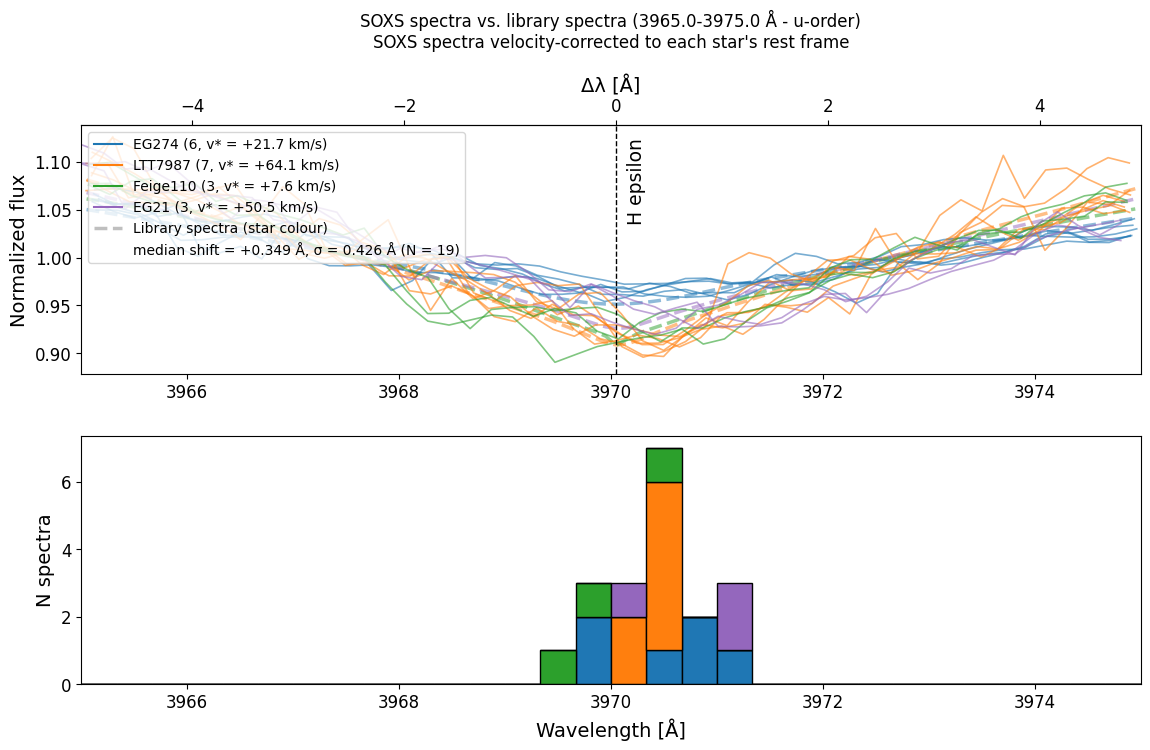

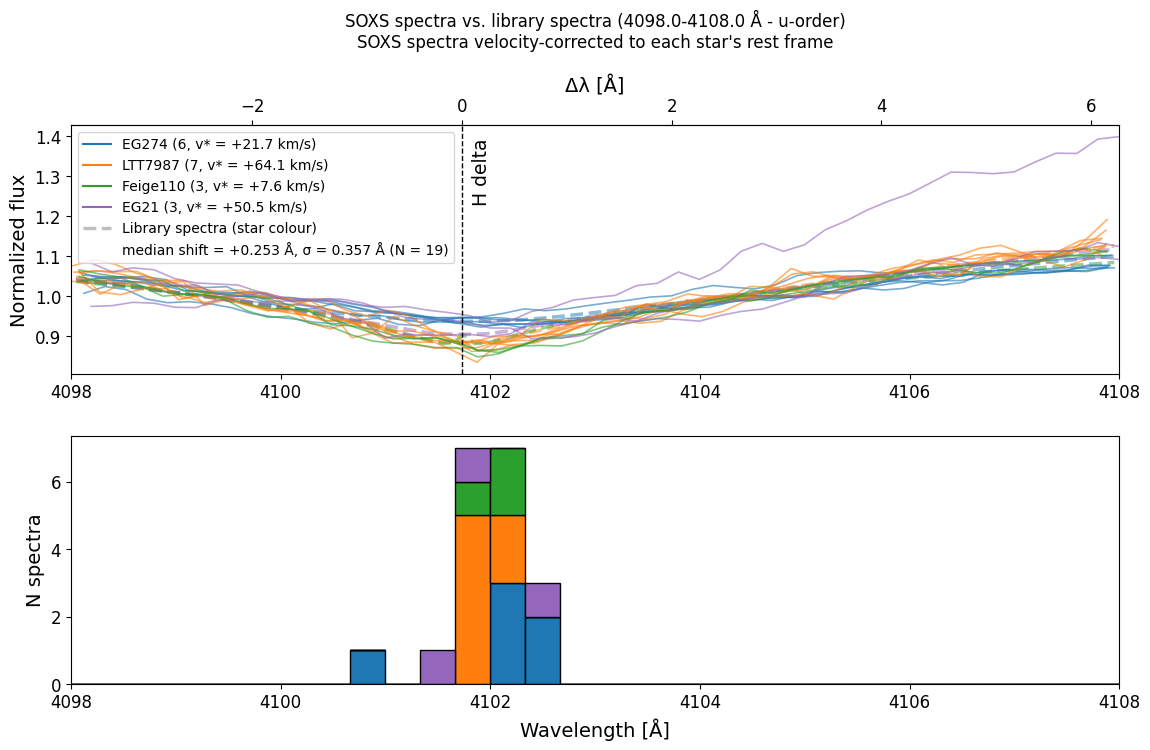

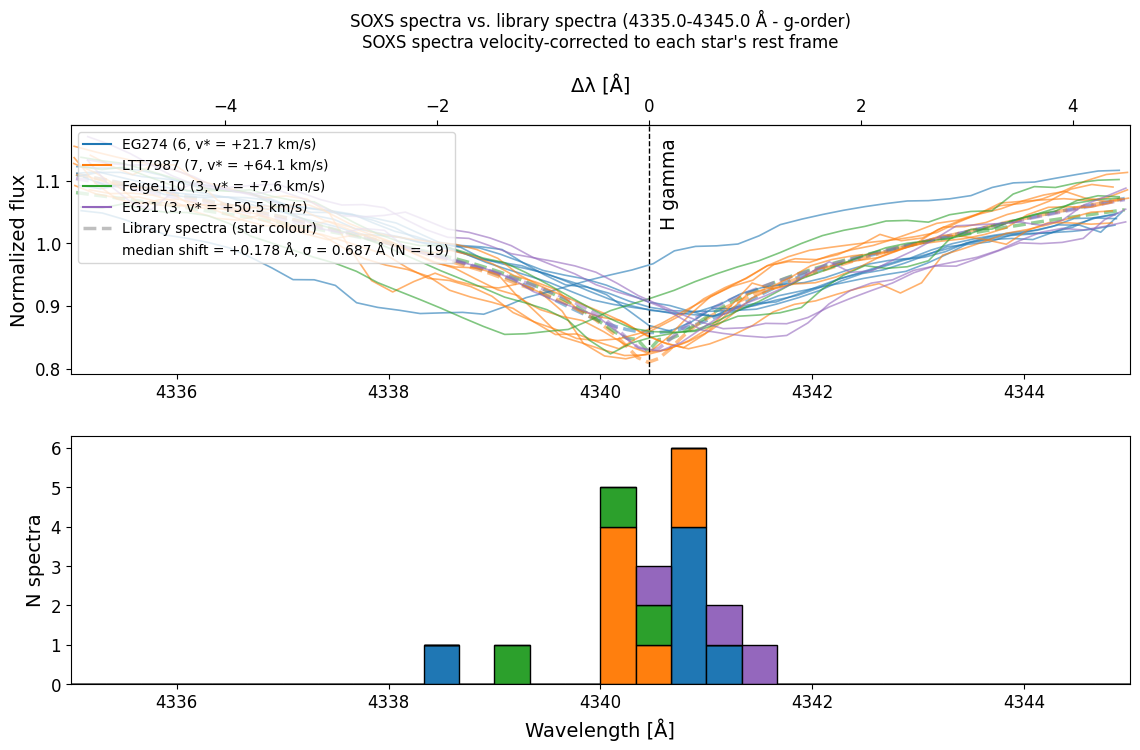

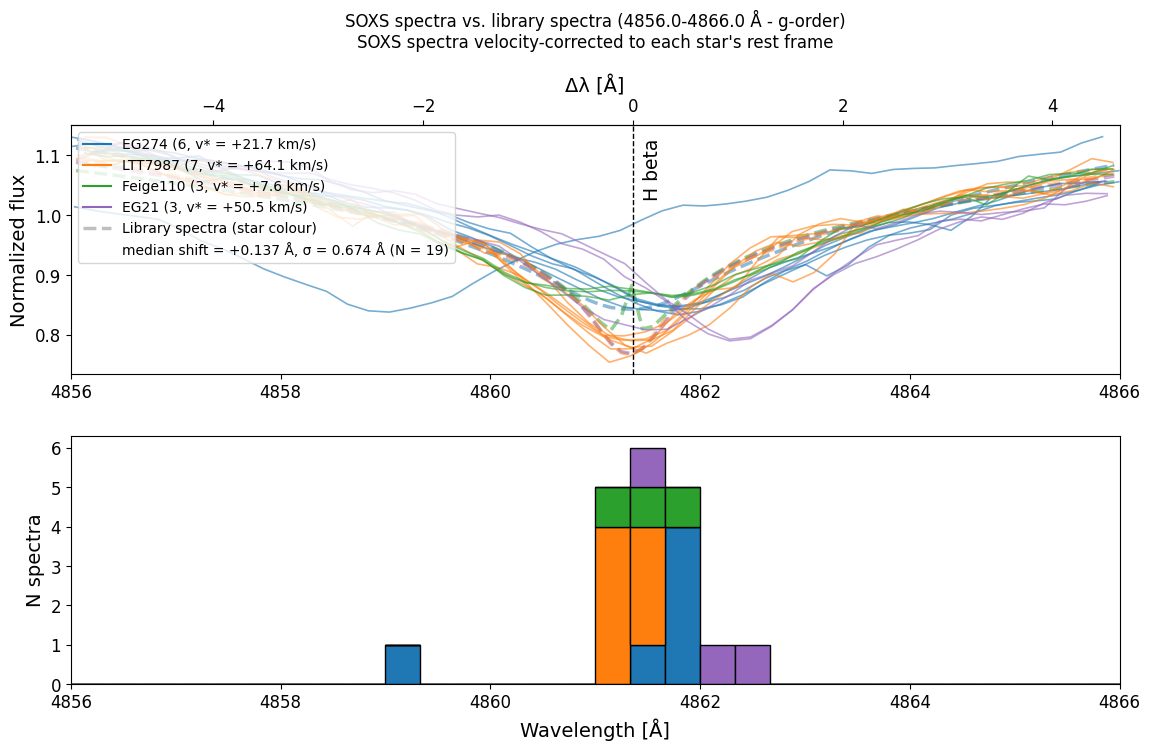

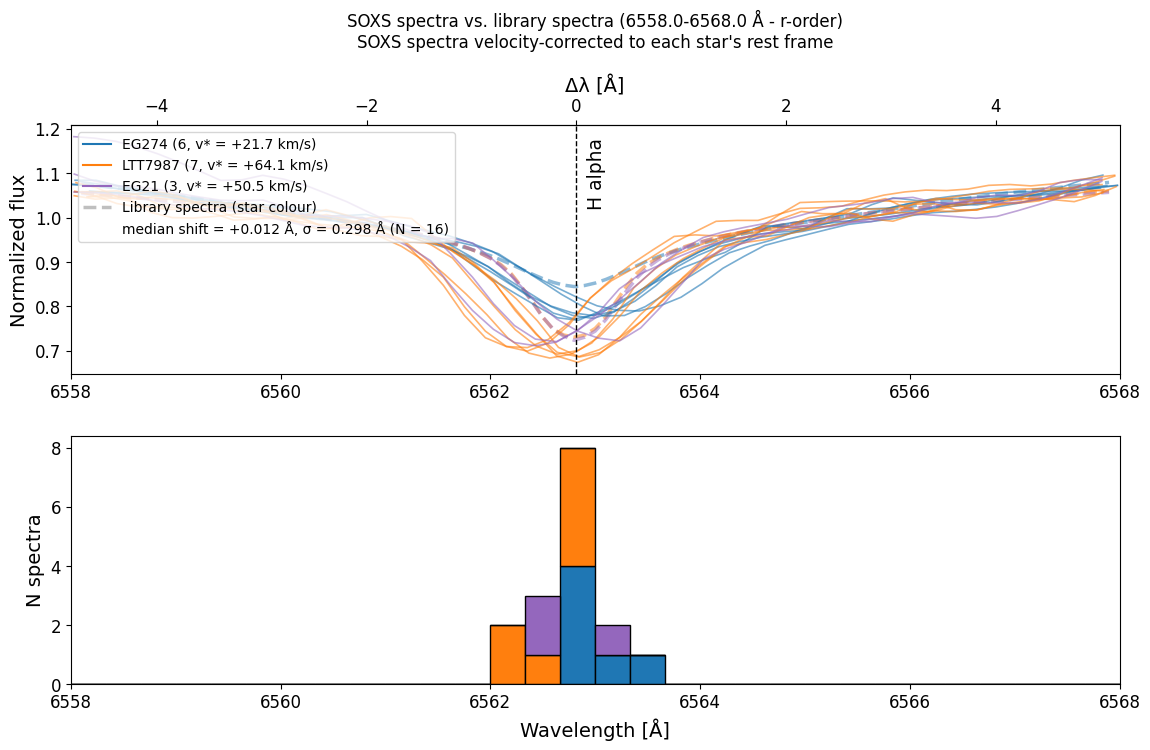

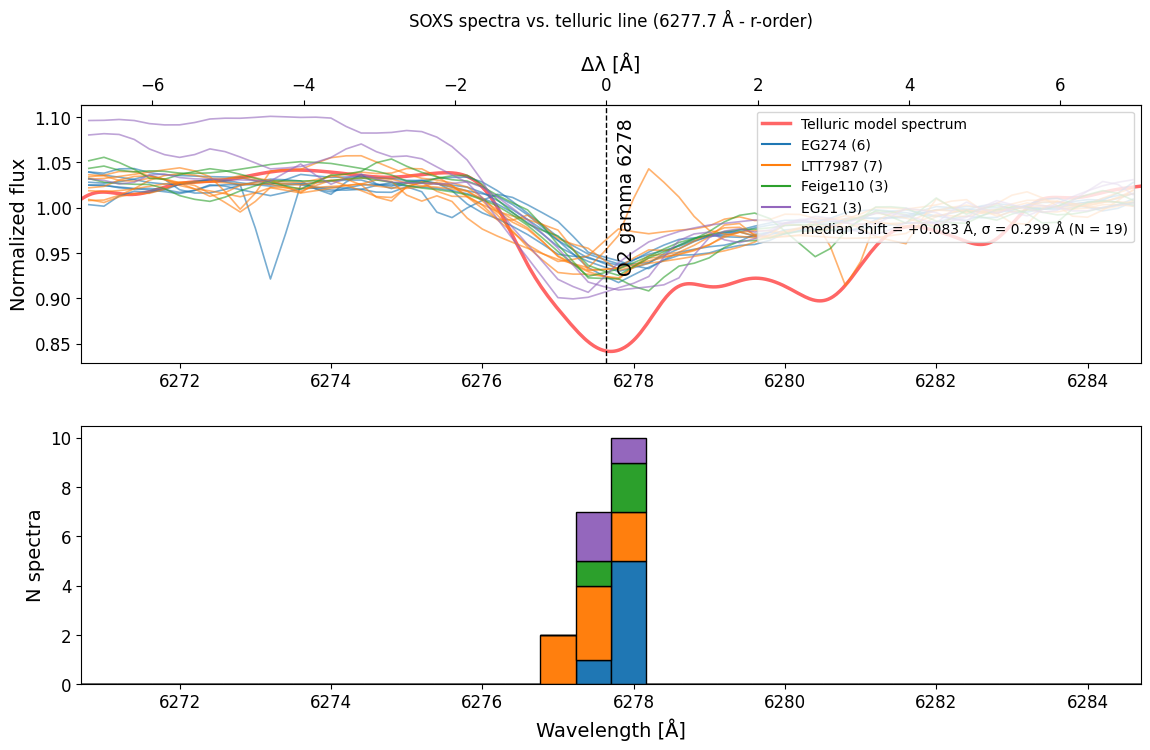

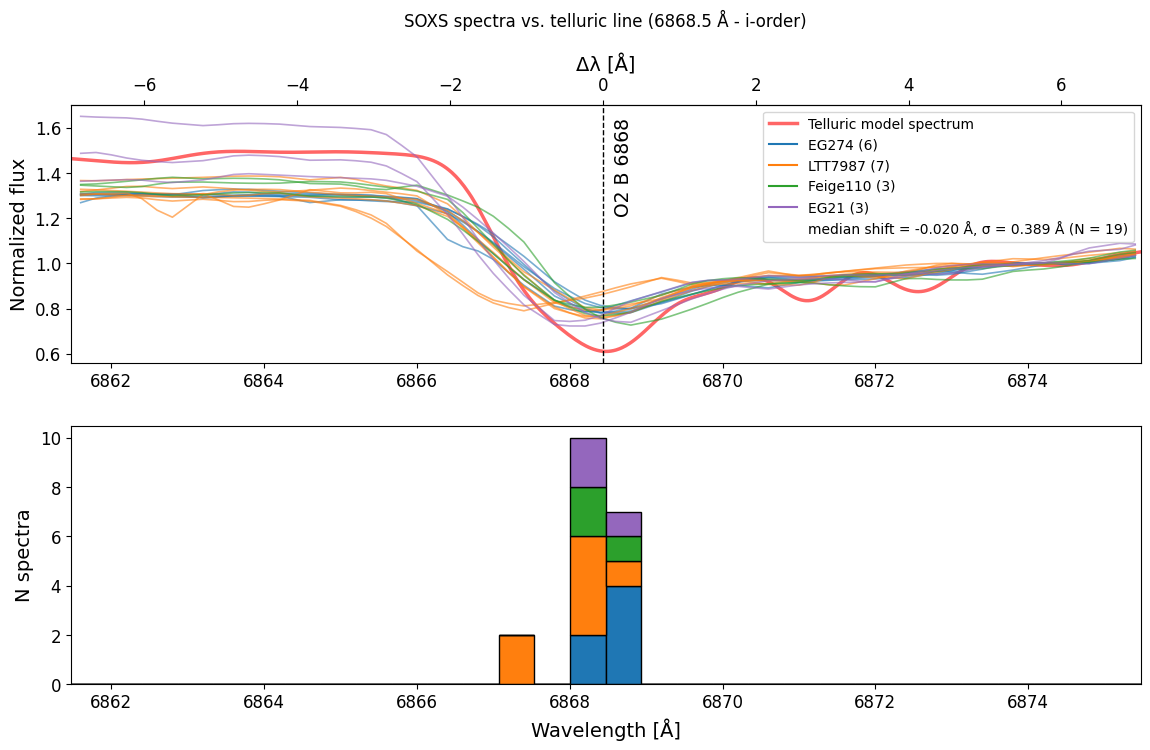

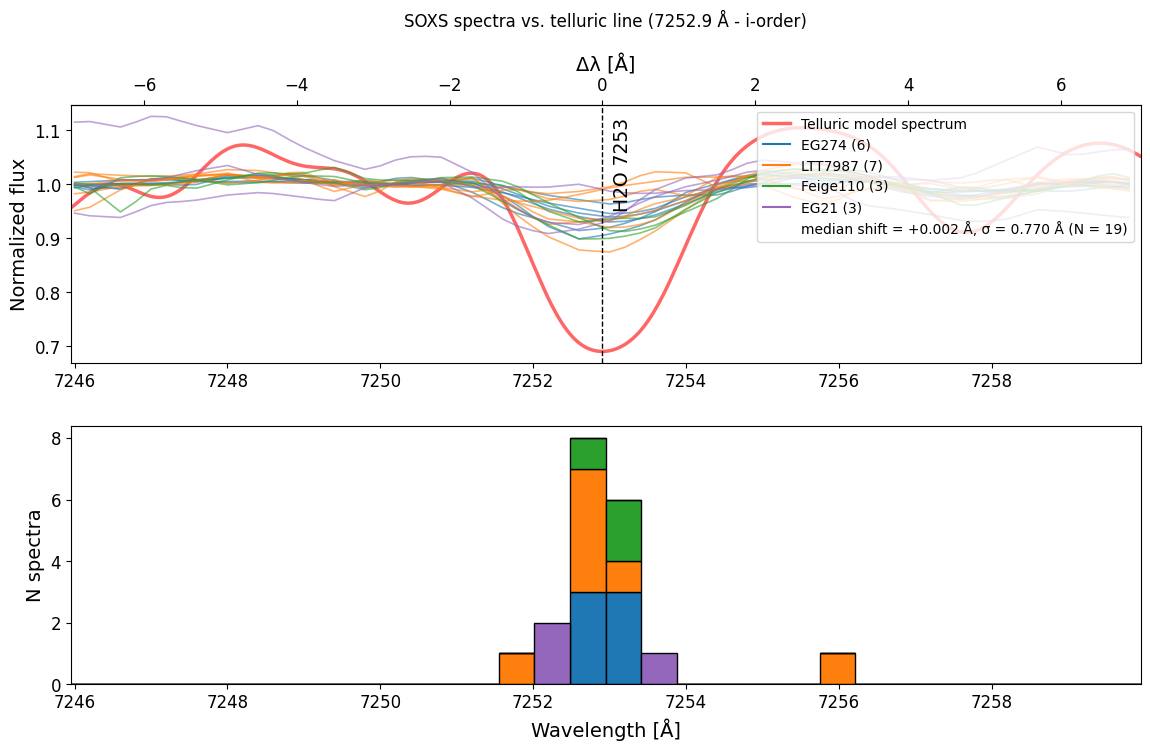

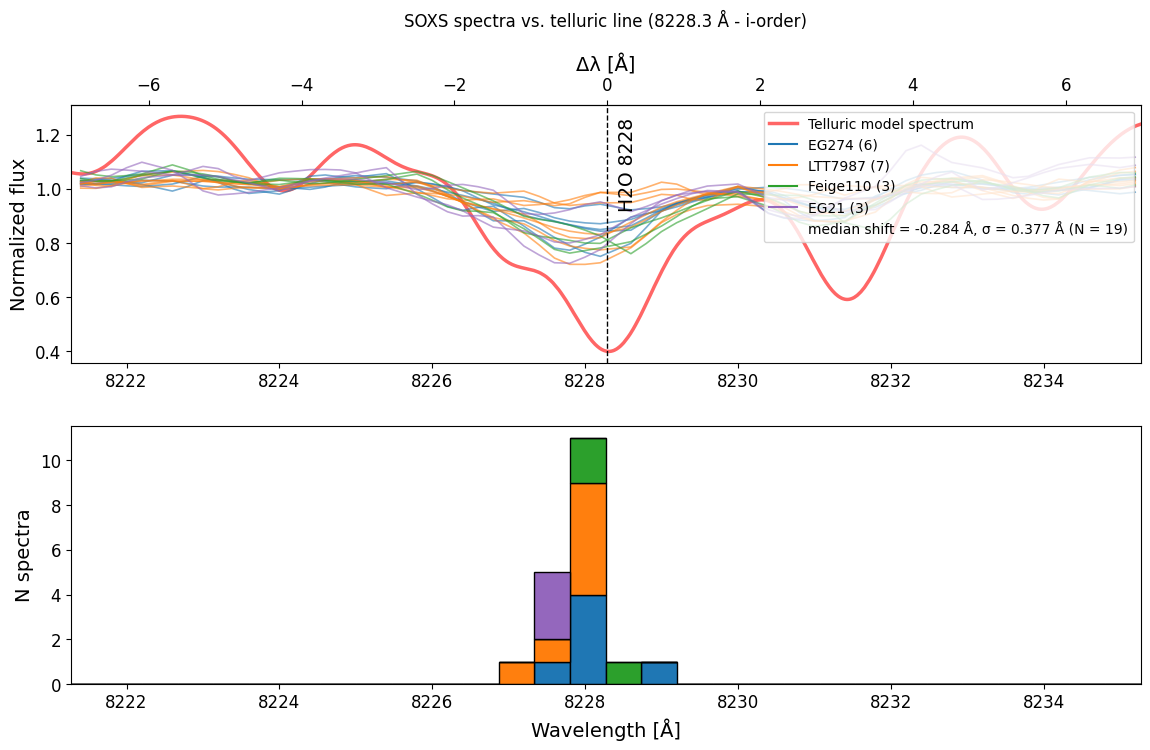

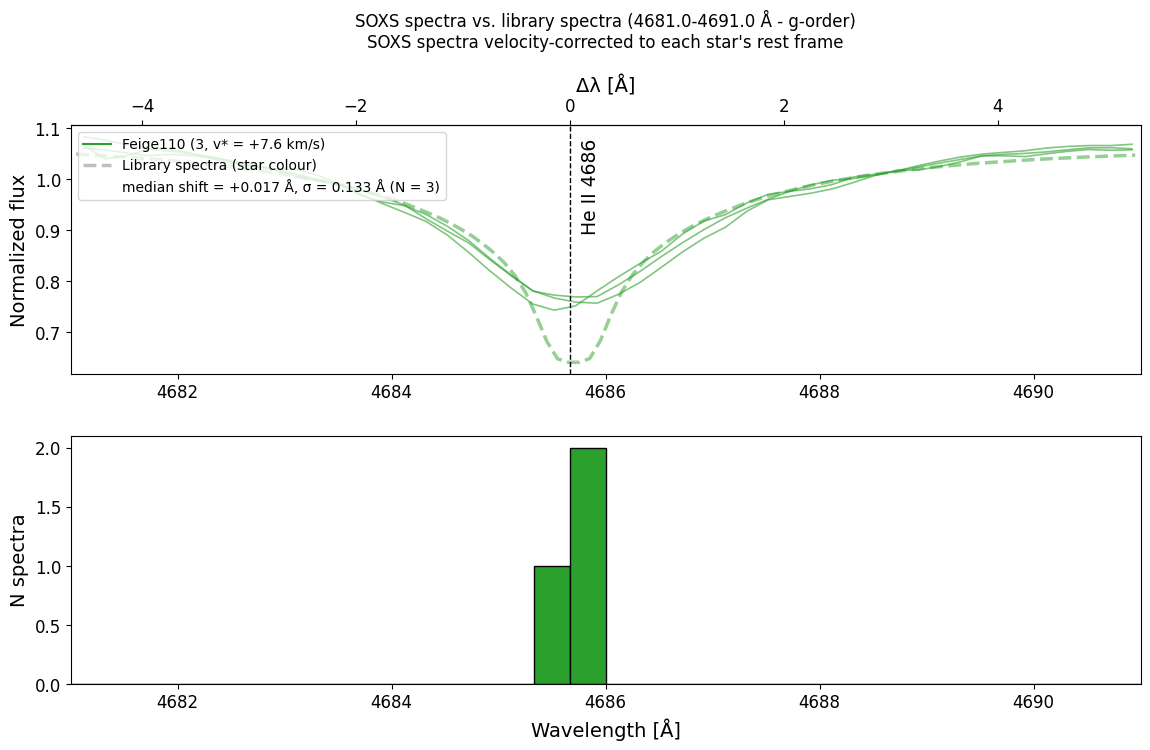

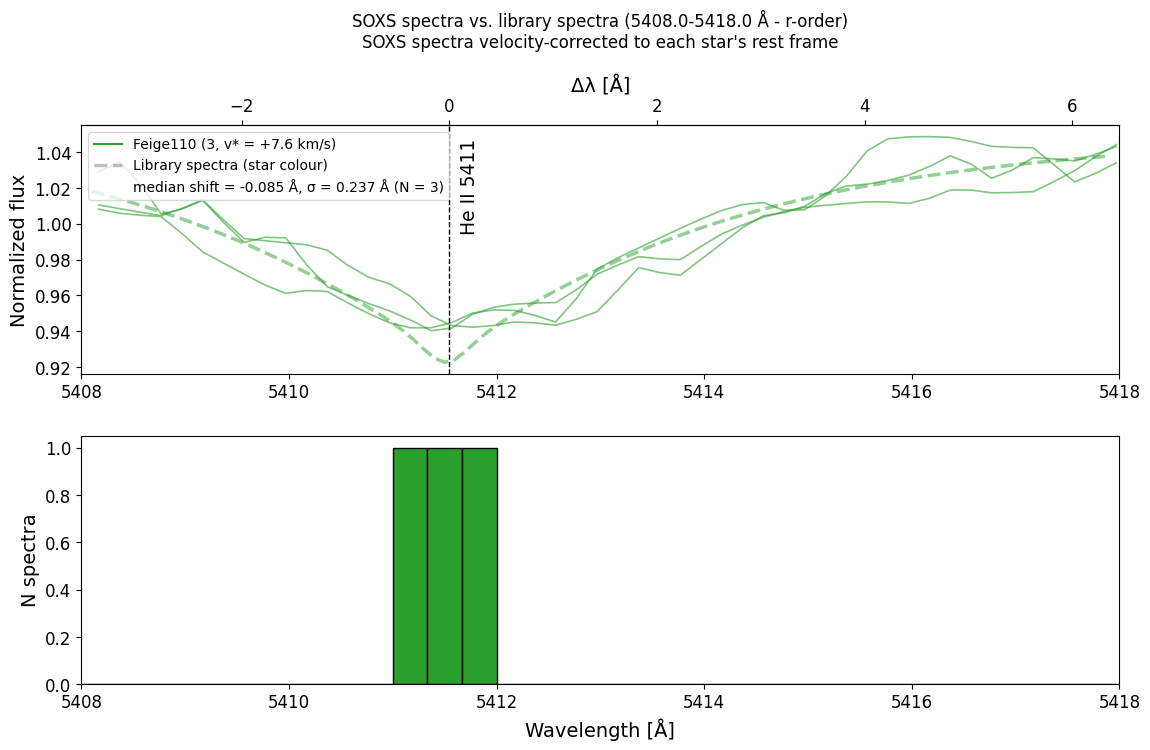

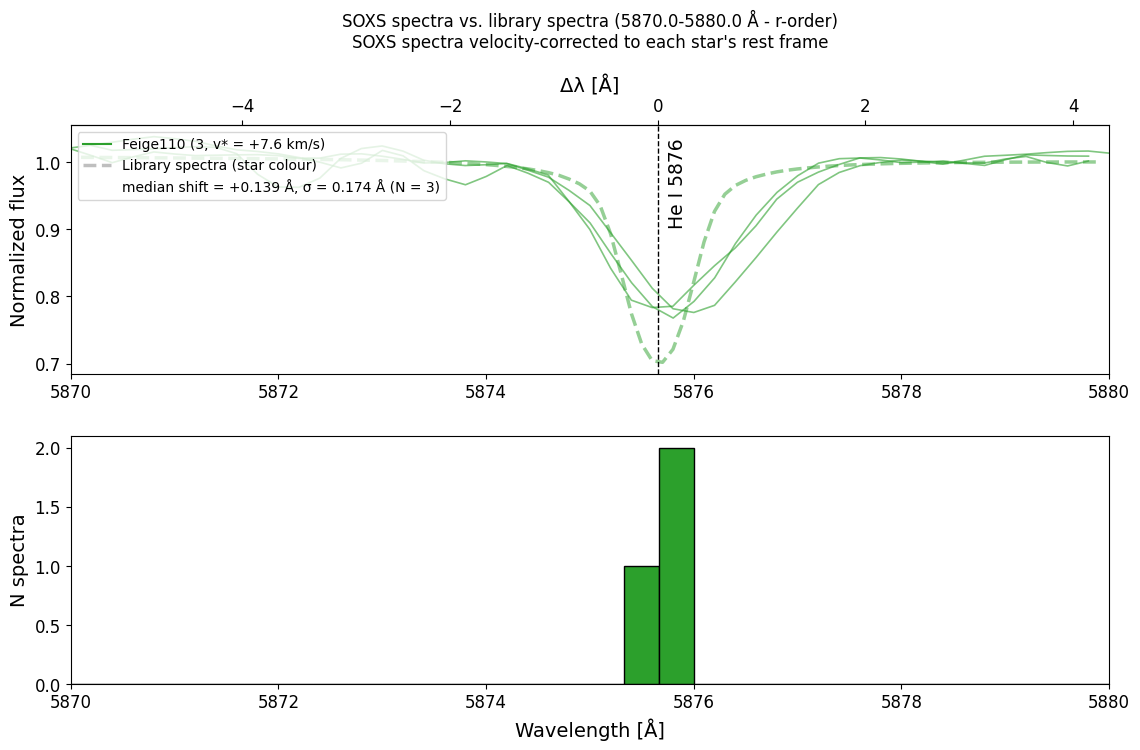

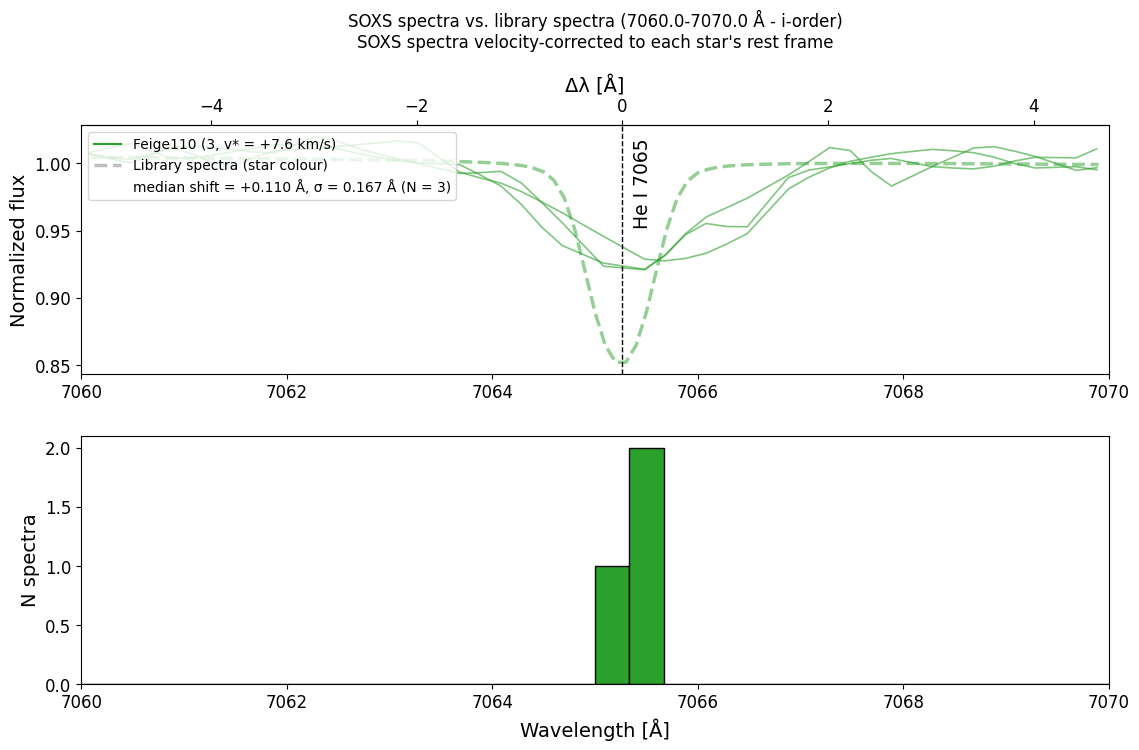

In [114]:
# PLOT: ONE COMPARISON PLOT PER MEASURED LINE WITH EVERY STAR TOGETHER (+ OPTIONAL PER-STAR METRICS PLOTS)
# (REUSES THE MEASUREMENTS FROM resultsDf ABOVE -- NO RE-FITTING)
spectraByStar = {starName: get_spectra_for_star(standardsData, details, starName) for starName in resultsDf['Star'].unique()}

lineKeys = ['LineType', 'Order', 'WindowMinAngstrom', 'WindowMaxAngstrom']
for (lineType, order, windowMin, windowMax), lineRowsDf in resultsDf.groupby(lineKeys, sort=False):
    isTelluric = lineType == 'telluric'
    telluricLine = (windowMin + windowMax) / 2.0 if isTelluric else False

    starGroups = []
    for starName, starRowsDf in lineRowsDf.groupby('Star', sort=False):
        matchedSpectra, matchedDetails = spectraByStar[starName]
        if isTelluric:
            libraryWaveNmArg, libraryFluxArg, vStarKms = telluricSpectrumWaveAngstrom / 10.0, telluricSpectrumFlux, None
        else:
            libraryWaveNmArg, libraryFluxArg = data['WAVE'], data[starName]
            fittedVelocity = starVelocitiesDf.loc[starVelocitiesDf['Star'] == starName, 'VStarKms']
            vStarKms = fittedVelocity.iloc[0] if len(fittedVelocity) else None

        resultsForStar = starRowsDf.to_dict('records')
        starGroups.append({
            'starName': starName,
            'color': STAR_COLORS[starName],
            'spectra': matchedSpectra,
            'details': matchedDetails,
            'libraryWaveNm': libraryWaveNmArg,
            'libraryFlux': libraryFluxArg,
            'resultRows': resultsForStar,
            'vStarKms': vStarKms,
        })

        if PLOT_METRICS:
            windowTag = f"{starName}_telluric_line_{telluricLine:.0f}A" if isTelluric else f"{starName}_{windowMin:.0f}-{windowMax:.0f}A"
            plot_metrics(
                starName, windowMin, windowMax, resultsForStar,
                savePath=f"{PLOTS_DIR}{windowTag}_metrics.png",
            )

    lineTag = f"telluric_line_{telluricLine:.0f}A" if isTelluric else f"stellar_{windowMin:.0f}-{windowMax:.0f}A"
    plot_comparison(
        windowMin, windowMax, starGroups, order,
        telluric=telluricLine,
        savePath=f"{PLOTS_DIR}{lineTag}_comparison.png",
    )

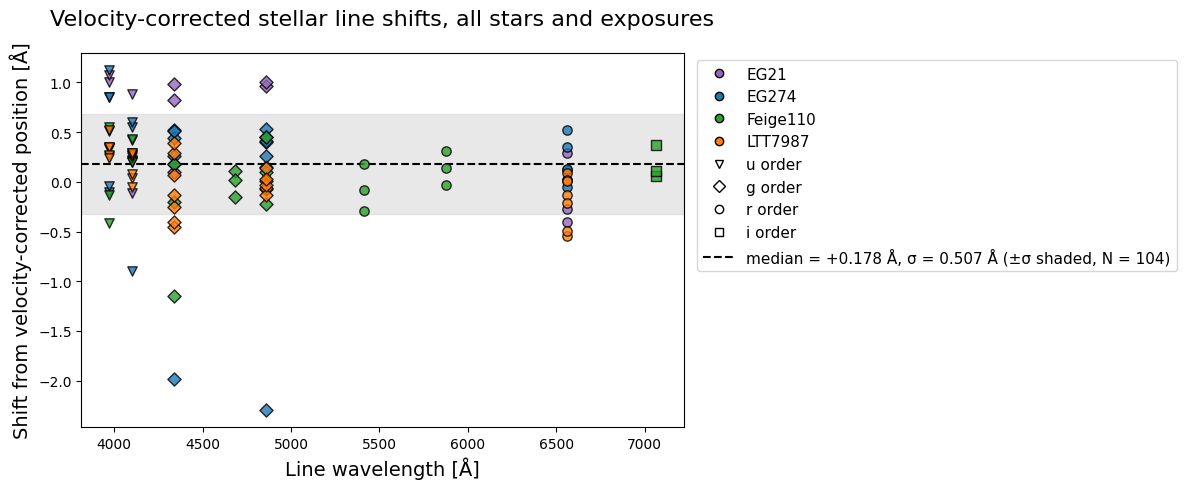

In [115]:
# DIAGNOSTIC PLOT: VELOCITY-CORRECTED STELLAR LINE SHIFT AGAINST WAVELENGTH, EVERY STAR AND EXPOSURE IN ONE PANEL.
# EACH SHIFT HAS THE STAR'S FITTED VELOCITY REMOVED, SO WHAT REMAINS IS THE WAVELENGTH-SOLUTION ERROR.
# A WAVELENGTH-SOLUTION ERROR IN ONE ORDER SHOWS AS AN OFFSET OF THAT ORDER'S MARKERS.
# THE MEDIAN AND σ POOL EVERY STAR, ORDER AND EXPOSURE: σ IS THE SCATTER OF SINGLE LINES, NOT AN ERROR ON THE MEDIAN.
# STARS WITHOUT A FITTED VELOCITY HAVE NaN RESIDUALS AND ARE LEFT OUT.
stellarDf = resultsDf[(resultsDf['LineType'] == 'stellar') & np.isfinite(resultsDf['ResidualAngstrom'])]

if len(stellarDf) == 0:
    display(Markdown("**Warning:** no velocity-corrected stellar line measurements -- star velocity diagnostic plot skipped."))
else:
    residualValues = stellarDf['ResidualAngstrom'].to_numpy()
    medianResidual = np.median(residualValues)
    stdResidual = np.std(residualValues, ddof=1) if len(residualValues) > 1 else np.nan

    fig, ax = plt.subplots(figsize=(12, 5))
    if np.isfinite(stdResidual):
        ax.axhspan(medianResidual - stdResidual, medianResidual + stdResidual, color='lightgrey', alpha=0.5, zorder=0)
    ax.axhline(medianResidual, color='black', linestyle='--', zorder=1)
    for (starName, order), groupDf in stellarDf.groupby(['Star', 'Order']):
        ax.scatter(
            groupDf['LineWavelengthAngstrom'], groupDf['ResidualAngstrom'],
            color=STAR_COLORS.get(starName, 'grey'), marker=ORDER_MARKERS.get(order, '^'),
            edgecolor='black', s=45, alpha=0.8, zorder=2,
        )

    # LEGEND FROM PROXY HANDLES: ONE ENTRY PER STAR (COLOUR), ONE PER ORDER (MARKER, WITH ITS MEDIAN), AND THE GLOBAL STATISTICS
    orderMedians = stellarDf.groupby('Order')['ResidualAngstrom'].median()
    starHandles = [
        Line2D([], [], marker='o', linestyle='', color=STAR_COLORS.get(starName, 'grey'), markeredgecolor='black', label=starName)
        for starName in sorted(stellarDf['Star'].unique())
    ]
    # ORDERS IN WAVELENGTH ORDER, THEN ANY ORDER WITHOUT ITS OWN MARKER
    presentOrders = set(stellarDf['Order'])
    legendOrders = [order for order in ORDER_MARKERS if order in presentOrders] + sorted(presentOrders - set(ORDER_MARKERS))
    orderHandles = [
        Line2D([], [], marker=ORDER_MARKERS.get(order, '^'), linestyle='', color='white', markeredgecolor='black', label=f"{order} order: median = {orderMedians[order]:+.3f} Å")
        for order in legendOrders
    ]
    statsHandle = Line2D([], [], color='black', linestyle='--', label=f"all orders: median = {medianResidual:+.3f} Å, σ = {stdResidual:.3f} Å (±σ shaded, N = {len(residualValues)})")
    # LEGEND OUTSIDE THE AXES SO IT HIDES NO POINTS
    ax.legend(handles=starHandles + orderHandles + [statsHandle], fontsize=11, loc='upper left', bbox_to_anchor=(1.01, 1.0))

    ax.set_title("Velocity-corrected stellar line shifts, all stars and exposures", pad=20, fontsize=16)
    ax.set_xlabel("Line wavelength [Å]", fontsize=14)
    ax.set_ylabel("Shift from velocity-corrected position [Å]", fontsize=14)
    fig.tight_layout()
    fig.savefig(f"{PLOTS_DIR}star_velocity_diagnostic.png", dpi=150, bbox_inches='tight')
    plt.show()

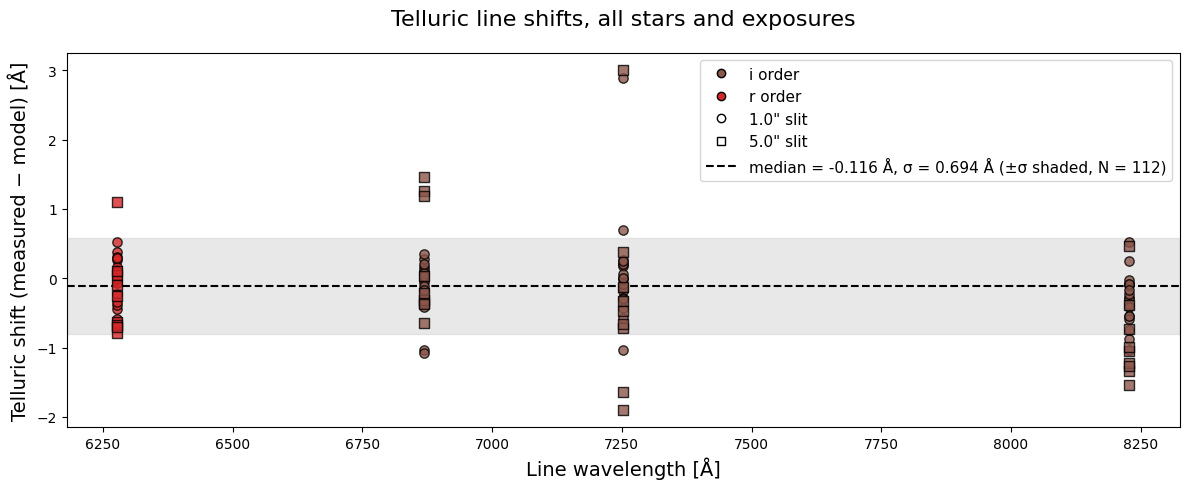

In [116]:
# DIAGNOSTIC PLOT: TELLURIC LINE SHIFT AGAINST WAVELENGTH, EVERY STAR, EXPOSURE AND SLIT IN ONE PANEL.
# TELLURIC LINES FORM IN THE EARTH'S ATMOSPHERE, SO ANY SHIFT IS A WAVELENGTH-SOLUTION ERROR (NO VELOCITY TO REMOVE).
# THE MEDIAN AND σ POOL EVERY ORDER, SLIT AND EXPOSURE: σ IS THE SCATTER OF SINGLE LINES, NOT AN ERROR ON THE MEDIAN.

if len(telluricAllSlitsDf) == 0:
    display(Markdown("**Warning:** no telluric line measurements -- telluric shift plot skipped."))
else:
    shiftValues = telluricAllSlitsDf['ShiftAngstrom'].to_numpy()
    medianShift = np.median(shiftValues)
    stdShift = np.std(shiftValues, ddof=1) if len(shiftValues) > 1 else np.nan

    fig, ax = plt.subplots(figsize=(12, 5))
    if np.isfinite(stdShift):
        ax.axhspan(medianShift - stdShift, medianShift + stdShift, color='lightgrey', alpha=0.5, zorder=0)
    ax.axhline(medianShift, color='black', linestyle='--', zorder=1)
    for (order, slit), groupDf in telluricAllSlitsDf.groupby(['Order', 'Slit']):
        ax.scatter(
            groupDf['LineWavelengthAngstrom'], groupDf['ShiftAngstrom'],
            color=ORDER_COLORS.get(order, 'grey'), marker=SLIT_MARKERS.get(slit, '^'),
            edgecolor='black', s=45, alpha=0.8, zorder=2,
        )

    # LEGEND FROM PROXY HANDLES: ONE ENTRY PER ORDER (COLOUR, WITH ITS MEDIAN), ONE PER SLIT (MARKER), AND THE GLOBAL STATISTICS
    orderMedians = telluricAllSlitsDf.groupby('Order')['ShiftAngstrom'].median()
    # ORDERS IN WAVELENGTH ORDER, THEN ANY ORDER WITHOUT ITS OWN COLOUR
    presentOrders = set(telluricAllSlitsDf['Order'])
    legendOrders = [order for order in ORDER_COLORS if order in presentOrders] + sorted(presentOrders - set(ORDER_COLORS))
    orderHandles = [
        Line2D([], [], marker='o', linestyle='', color=ORDER_COLORS.get(order, 'grey'), markeredgecolor='black', label=f"{order} order: median = {orderMedians[order]:+.3f} Å")
        for order in legendOrders
    ]
    slitHandles = [
        Line2D([], [], marker=SLIT_MARKERS.get(slit, '^'), linestyle='', color='white', markeredgecolor='black', label=f'{slit:.1f}" slit')
        for slit in sorted(telluricAllSlitsDf['Slit'].unique())
    ]
    statsHandle = Line2D([], [], color='black', linestyle='--', label=f"all orders: median = {medianShift:+.3f} Å, σ = {stdShift:.3f} Å (±σ shaded, N = {len(shiftValues)})")
    # LEGEND OUTSIDE THE AXES SO IT HIDES NO POINTS
    ax.legend(handles=orderHandles + slitHandles + [statsHandle], fontsize=11, loc='upper left', bbox_to_anchor=(1.01, 1.0))

    ax.set_title("Telluric line shifts, all stars and exposures", pad=20, fontsize=16)
    ax.set_xlabel("Line wavelength [Å]", fontsize=14)
    ax.set_ylabel("Telluric shift (measured − model) [Å]", fontsize=14)
    fig.tight_layout()
    fig.savefig(f"{PLOTS_DIR}telluric_shift_diagnostic.png", dpi=150, bbox_inches='tight')
    plt.show()


<!-- # Telluric sanity-check plots

Plots every folder spectrum within each `TELLURIC_WINDOWS` range, one plot per window with every star together (each star in its own colour). These are broad atmospheric-absorption bands rather than single stellar lines, so there is no library comparison or shift measurement here -- just a by-eye check that the telluric features line up consistently across exposures and stars. -->

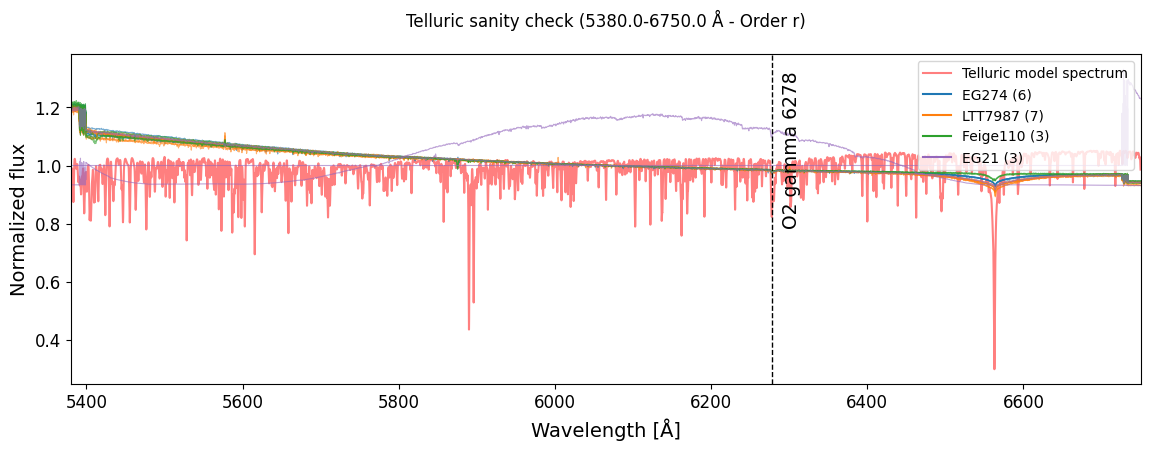

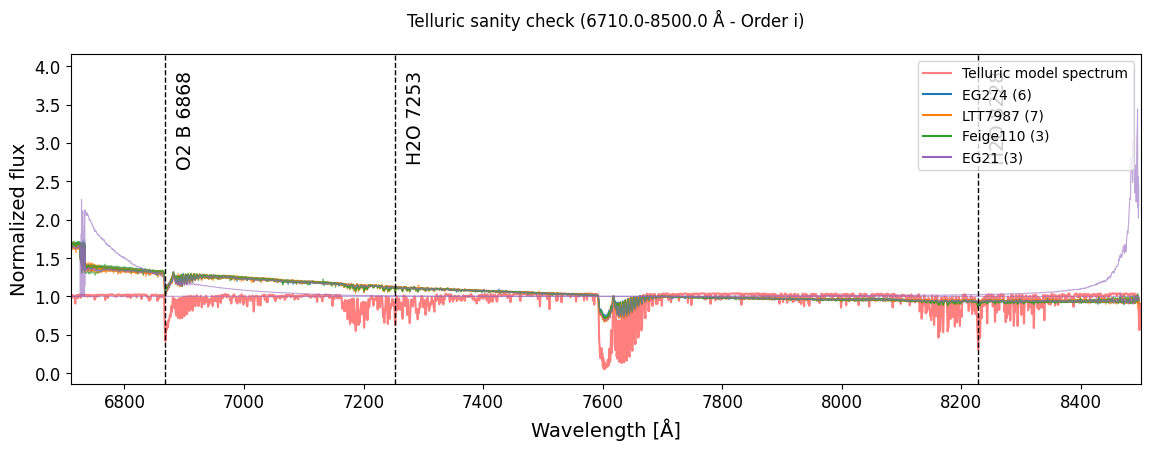

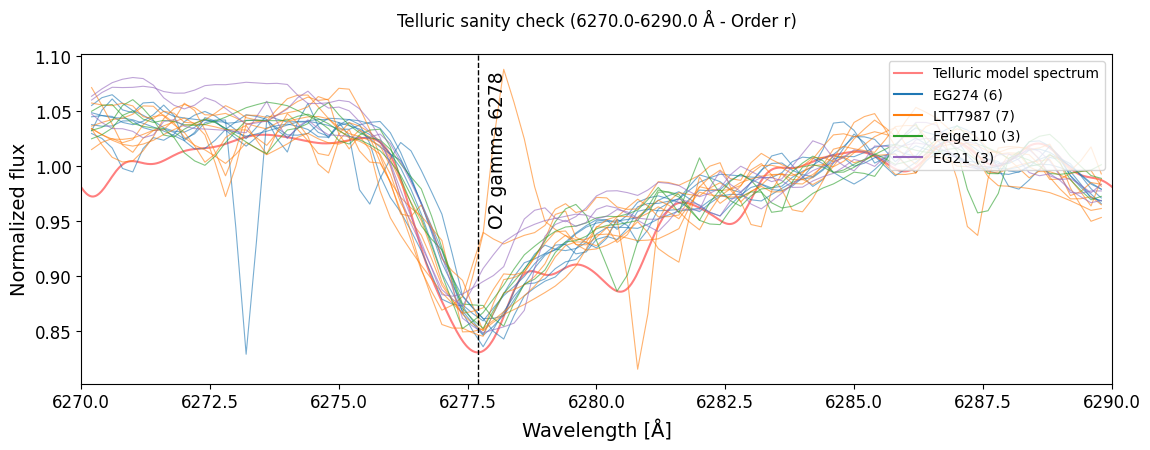

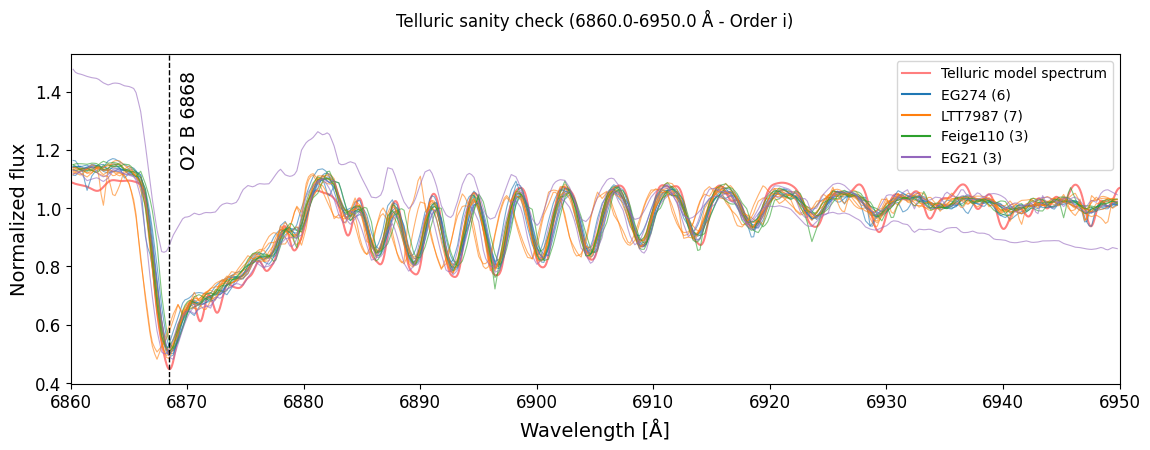

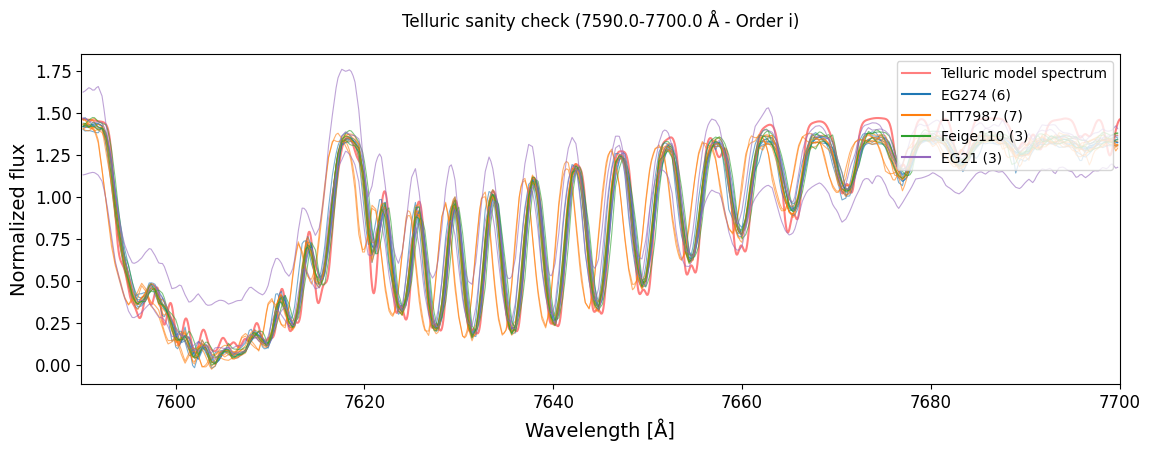

In [117]:
# DRIVER: ONE TELLURIC SANITY-CHECK PLOT PER TELLURIC WINDOW WITH EVERY STAR TOGETHER
telluricStarGroups = []
for starName in STANDARD_STARS:
    matchedSpectra, _ = get_spectra_for_star(standardsData, details, starName)
    if matchedSpectra:
        telluricStarGroups.append({'starName': starName, 'color': STAR_COLORS[starName], 'spectra': matchedSpectra})

if not telluricStarGroups:
    print("[WARNING] no star has spectra, telluric sanity-check plots skipped")

for windowMin, windowMax in (TELLURIC_WINDOWS if telluricStarGroups else []):
    order = assign_spectral_order(windowMin, windowMax, spectralFormatDf)

    if ORDERS_TO_INSPECT is not None and order not in ORDERS_TO_INSPECT:
        continue

    plot_telluric_window(
        windowMin, windowMax, telluricStarGroups, order,
        telluricSpectrumWaveAngstrom, telluricSpectrumFlux,
        savePath=f"{PLOTS_DIR}telluric_window_{windowMin:.0f}-{windowMax:.0f}A.png",
    )